# Лабораторна робота № 5-6
## Нейронна мережа і регуляризація

**Виконав:** Новак Сергій, ФЕІ-43с

**Мета.** Реалізувати повнозв'язну нейронну мережу (MLP, Multilayer Perceptron - багатошаровий перцептрон) з нуля на NumPy: прямий прохід, зворотне поширення помилки (backpropagation), SGD (Stochastic Gradient Descent — стохастичний градієнтний спуск), збереження та відновлення ваг. Далі експериментально дослідити, як L1, L2, Dropout, weight clipping і gradient clipping впливають на розподіл ваг, розрідженість (sparsity), кількість мертвих нейронів і якість класифікації.

**Дані.** FashionMNIST — зображення одягу 28×28 у відтінках сірого, 10 класів. Офіційні файли лежать у `data/fashion/`.

**Обмеження умови.** Прямий прохід, backpropagation, оновлення ваг і всі методи регуляризації реалізовано власноруч на NumPy. Автоматичне диференціювання та готові нейромережі не використовуються. `scikit-learn` не потрібен, `pandas` і `matplotlib` використовуються лише для таблиць і графіків.

In [1]:
import gzip
import json
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SEED = 42
np.random.seed(SEED)

COLORS = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948",
    "muted": "#8a8984", "ink": "#52514e",
}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})
pd.set_option("display.max_colwidth", 200)

DATA_DIR = Path("data/fashion")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

display(pd.Series({
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
}, name="версія").to_frame())

,версія
Python,3.12.11
numpy,2.5.4
pandas,3.1.1
matplotlib,3.11.2


## 0. Дані

Читаємо офіційні файли FashionMNIST (формат IDX, стиснутий gzip). Кожне зображення 28×28 розгортаємо у вектор довжини $28 \cdot 28 = 784$, а значення пікселів ділимо на 255, щоб вони лежали в діапазоні $[0, 1]$.

Щоб експерименти виконувались за прийнятний час, використовуємо підмножини, як дозволяє умова. Усі експерименти працюють з **тими самими** підмножинами:

- **Train** — 20 000 зображень з офіційного тренувального набору;
- **Validation** — інші 10 000 зображень з офіційного тренувального набору, які не перетинаються з Train; на них порівнюємо методи;
- **Test** — офіційний тестовий набір (10 000), використовується один раз наприкінці.

In [2]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


def read_idx_images(path):
    with gzip.open(path, "rb") as file:
        raw = np.frombuffer(file.read(), dtype=np.uint8, offset=16)
    return raw.reshape(-1, 28 * 28).astype(np.float32) / 255.0


def read_idx_labels(path):
    with gzip.open(path, "rb") as file:
        return np.frombuffer(file.read(), dtype=np.uint8, offset=8).astype(np.int64)


X_full = read_idx_images(DATA_DIR / "train-images-idx3-ubyte.gz")
y_full = read_idx_labels(DATA_DIR / "train-labels-idx1-ubyte.gz")
X_test = read_idx_images(DATA_DIR / "t10k-images-idx3-ubyte.gz")
y_test = read_idx_labels(DATA_DIR / "t10k-labels-idx1-ubyte.gz")

N_TRAIN, N_VAL = 20_000, 10_000
order = np.random.default_rng(SEED).permutation(len(y_full))
train_idx, val_idx = order[:N_TRAIN], order[N_TRAIN:N_TRAIN + N_VAL]
X_train, y_train = X_full[train_idx], y_full[train_idx]
X_val, y_val = X_full[val_idx], y_full[val_idx]

assert len(np.intersect1d(train_idx, val_idx)) == 0
print(f"Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")
print(f"Діапазон пікселів: [{X_train.min():.1f}, {X_train.max():.1f}]")
display(pd.DataFrame({
    "Train": np.bincount(y_train, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10),
}, index=CLASS_NAMES).T)

Train: (20000, 784), Validation: (10000, 784), Test: (10000, 784)
Діапазон пікселів: [0.0, 1.0]


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
Train,1973,2000,2040,1983,1974,2037,1951,2041,1947,2054
Validation,1051,1033,992,945,997,987,980,989,1011,1015
Test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


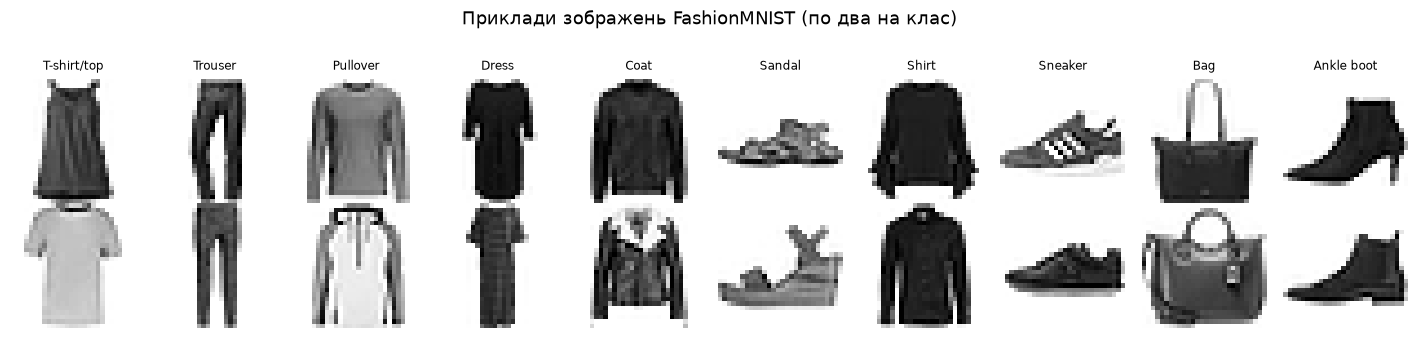

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for label in range(10):
    examples = np.flatnonzero(y_train == label)[:2]
    for row, index in enumerate(examples):
        axes[row, label].imshow(X_train[index].reshape(28, 28), cmap="gray_r")
        axes[row, label].axis("off")
    axes[0, label].set_title(CLASS_NAMES[label], fontsize=8, fontweight="normal")
fig.suptitle("Приклади зображень FashionMNIST (по два на клас)", y=1.02)
plt.tight_layout()
plt.show()

**Коментар.** Класи в Train і Validation майже рівномірні (≈ 10% кожен), тому accuracy (частка правильних відповідей) — адекватна основна метрика. Найважче розрізняти схожі за формою речі верхнього одягу: T-shirt, Pullover, Coat, Shirt.

# Блок 1. Реалізація нейронної мережі з нуля

## 1.1 Архітектура

$$784 \;\xrightarrow{\text{ReLU}}\; 256 \;\xrightarrow{\text{ReLU}}\; 128 \;\xrightarrow{\text{ReLU}}\; 64 \;\xrightarrow{\text{Softmax}}\; 10$$

- **3 приховані шари** (256, 128, 64 нейрони) з активацією ReLU (Rectified Linear Unit): $\text{ReLU}(z) = \max(0, z)$;
- вихідний шар — Softmax на 10 класів;
- функція втрат — categorical cross-entropy (категоріальна крос-ентропія): $L_{CE} = -\frac1N \sum_i \log p_{i, y_i}$;
- ініціалізація He: $W_{ij} \sim \mathcal N(0, 2/n_{in})$; зміщення $b = 0$;
- оптимізатор — mini-batch SGD з постійним кроком $\eta$.

Разом $784 \cdot 256 + 256 \cdot 128 + 128 \cdot 64 + 64 \cdot 10$ ваг плюс зміщення — приблизно 242 тисячі параметрів.

## 1.2 Клас нейронної мережі

Клас зберігає матриці ваг, вектори зміщень, проміжні $Z^{(l)}$ та $A^{(l)}$, маски Dropout і всі параметри конфігурації. Регуляризацію закладено одразу, але з нульовими коефіцієнтами вона вимкнена, і мережа працює як звичайна.

- **Прямий прохід:** $Z^{(l)} = A^{(l-1)} W^{(l)} + b^{(l)}$, $A^{(l)} = \text{ReLU}(Z^{(l)})$. Для стабільності Softmax від логітів віднімається максимум рядка.
- **Dropout** (inverted): у режимі навчання $\tilde A = A \odot M / (1 - p)$, $M \sim \text{Bernoulli}(1 - p)$; в режимі inference (передбачення) маска не застосовується.
- **Backpropagation:** на виході $\delta^{(L)} = (P - Y)/N$. Далі $\delta^{(l)} = (\delta^{(l+1)} W^{(l+1)T}) \odot M^{(l)}/(1-p) \odot \mathbb 1[Z^{(l)} > 0]$; градієнти $\partial L/\partial W^{(l)} = A^{(l-1)T} \delta^{(l)}$ і $\partial L/\partial b^{(l)} = \sum_i \delta^{(l)}_i$.
- **Регуляризація ваг** (зміщення не регуляризуються): L2 додає до градієнта $\lambda_2 W$, L1 — субградієнт $\lambda_1 \operatorname{sign}(W)$, де $\operatorname{sign}(0) = 0$.
- **Gradient clipping** — масштабування всього градієнта на $\min(1, c / \lVert g \rVert_2)$ за **глобальною** L2-нормою всіх параметрів.
- **Weight clipping** — $W \leftarrow \operatorname{clip}(W, -c_w, c_w)$ після кожного кроку.

In [4]:
class NeuralNetwork:
    def __init__(self, layer_sizes, init="he", seed=SEED, dropout=0.0, l1=0.0, l2=0.0,
                 weight_clip=None, grad_clip=None, dtype="float32"):
        self.layer_sizes = [int(size) for size in layer_sizes]
        self.num_layers = len(self.layer_sizes) - 1
        self.init = init
        self.seed = int(seed)
        self.dropout = float(dropout)
        self.l1 = float(l1)
        self.l2 = float(l2)
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        self.dtype = np.dtype(dtype)
        self.weights, self.biases = self._initialize()
        self.dropout_rng = np.random.default_rng(self.seed + 1)
        self.z_values, self.activations, self.masks = [], [], []

    def _initialize(self):
        rng = np.random.default_rng(self.seed)
        weights, biases = [], []
        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            if self.init == "he":
                W = rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out))
            elif self.init == "xavier":
                limit = np.sqrt(6.0 / (n_in + n_out))
                W = rng.uniform(-limit, limit, size=(n_in, n_out))
            else:
                raise ValueError(f"Невідома ініціалізація: {self.init}")
            weights.append(W.astype(self.dtype))
            biases.append(np.zeros(n_out, dtype=self.dtype))
        return weights, biases

    def config(self):
        return {
            "layer_sizes": self.layer_sizes, "init": self.init, "seed": self.seed,
            "dropout": self.dropout, "l1": self.l1, "l2": self.l2,
            "weight_clip": self.weight_clip, "grad_clip": self.grad_clip, "dtype": self.dtype.name,
        }

    def forward(self, X, training=False, mask_seed=None):
        mask_rng = np.random.default_rng(mask_seed) if mask_seed is not None else self.dropout_rng
        self.activations, self.z_values, self.masks = [X], [], []
        A = X
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0, Z)
            mask = None
            if training and self.dropout > 0:
                mask = (mask_rng.random(A.shape) >= self.dropout).astype(self.dtype) / (1.0 - self.dropout)
                A = A * mask
            self.z_values.append(Z)
            self.masks.append(mask)
            self.activations.append(A)
        Z = A @ self.weights[-1] + self.biases[-1]
        Z = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
        self.z_values.append(Z)
        self.activations.append(P)
        return P

    @staticmethod
    def cross_entropy(P, y_true):
        return float(-np.mean(np.log(np.clip(P[np.arange(len(y_true)), y_true], 1e-12, None))))

    def regularization_penalty(self):
        penalty = 0.0
        if self.l1:
            penalty += self.l1 * sum(float(np.abs(W).sum()) for W in self.weights)
        if self.l2:
            penalty += 0.5 * self.l2 * sum(float((W.astype(np.float64) ** 2).sum()) for W in self.weights)
        return penalty

    def loss(self, X, y_true, training=False, mask_seed=None):
        return self.cross_entropy(self.forward(X, training, mask_seed), y_true) + self.regularization_penalty()

    def backward(self, y_true):
        n = y_true.shape[0]
        grads_W = [None] * self.num_layers
        grads_b = [None] * self.num_layers
        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1
        delta /= n
        for l in reversed(range(self.num_layers)):
            grads_W[l] = self.activations[l].T @ delta
            grads_b[l] = np.sum(delta, axis=0)
            if l > 0:
                delta = delta @ self.weights[l].T
                if self.masks[l - 1] is not None:
                    delta = delta * self.masks[l - 1]
                delta = delta * (self.z_values[l - 1] > 0)
        for l in range(self.num_layers):
            if self.l2:
                grads_W[l] = grads_W[l] + self.l2 * self.weights[l]
            if self.l1:
                grads_W[l] = grads_W[l] + self.l1 * np.sign(self.weights[l])
        return grads_W, grads_b

    def apply_gradients(self, grads_W, grads_b, learning_rate):
        global_norm = float(np.sqrt(sum(float((g.astype(np.float64) ** 2).sum()) for g in grads_W + grads_b)))
        scale = 1.0
        if self.grad_clip is not None and global_norm > self.grad_clip:
            scale = self.grad_clip / global_norm
        for l in range(self.num_layers):
            self.weights[l] -= learning_rate * scale * grads_W[l]
            self.biases[l] -= learning_rate * scale * grads_b[l]
            if self.weight_clip is not None:
                np.clip(self.weights[l], -self.weight_clip, self.weight_clip, out=self.weights[l])
        return global_norm, scale < 1.0

    def predict_proba(self, X, batch_size=5000):
        return np.vstack([self.forward(X[start:start + batch_size]) for start in range(0, len(X), batch_size)])

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def evaluate(self, X, y_true):
        P = self.predict_proba(X)
        return self.cross_entropy(P, y_true), float(np.mean(P.argmax(axis=1) == y_true))

    def save_weights(self, path):
        data = {f"W_{i}": W for i, W in enumerate(self.weights)}
        data.update({f"b_{i}": b for i, b in enumerate(self.biases)})
        data["config"] = np.array(json.dumps(self.config()))
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path)
        self.weights = [data[f"W_{i}"] for i in range(self.num_layers)]
        self.biases = [data[f"b_{i}"] for i in range(self.num_layers)]

    @classmethod
    def from_file(cls, path):
        config = json.loads(str(np.load(path)["config"]))
        model = cls(**config)
        model.load_weights(path)
        return model


ARCHITECTURE = [784, 256, 128, 64, 10]
probe = NeuralNetwork(ARCHITECTURE)
display(pd.DataFrame({
    "шар": [f"{n_in} → {n_out}" for n_in, n_out in zip(ARCHITECTURE[:-1], ARCHITECTURE[1:])],
    "тип": ["прихований (ReLU)"] * 3 + ["вихідний (Softmax)"],
    "W": [str(W.shape) for W in probe.weights],
    "std ваг після He": [f"{W.std():.4f}" for W in probe.weights],
    "теоретичне √(2/n_in)": [f"{np.sqrt(2 / n_in):.4f}" for n_in in ARCHITECTURE[:-1]],
    "параметрів": [W.size + b.size for W, b in zip(probe.weights, probe.biases)],
}))
print("Усього параметрів:", sum(W.size + b.size for W, b in zip(probe.weights, probe.biases)))
P_probe = probe.forward(X_train[:5])
print("Розмір виходу для батчу з 5 зображень:", P_probe.shape, "| суми ймовірностей:", np.round(P_probe.sum(axis=1), 6))

,шар,тип,W,std ваг після He,теоретичне √(2/n_in),параметрів
0,784 → 256,прихований (ReLU),"(784, 256)",0.0506,0.0505,200960
1,256 → 128,прихований (ReLU),"(256, 128)",0.0880,0.0884,32896
2,128 → 64,прихований (ReLU),"(128, 64)",0.1235,0.1250,8256
3,64 → 10,вихідний (Softmax),"(64, 10)",0.1772,0.1768,650


Усього параметрів: 242762
Розмір виходу для батчу з 5 зображень: (5, 10) | суми ймовірностей: [1. 1. 1. 1. 1.]


**Коментар.** Стандартне відхилення згенерованих ваг збігається з теоретичним $\sqrt{2/n_{in}}$, тобто He-ініціалізація працює правильно. Прямий прохід повертає для кожного зображення 10 ймовірностей, що в сумі дають 1.

## 1.3 Перевірка градієнтів чисельним диференціюванням

Порівнюємо аналітичні градієнти з backpropagation із чисельною оцінкою
$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}$ для випадково вибраних ваг і зміщень кожного шару. Мірою розбіжності є відносна похибка
$E = \frac{|g_{an} - g_{num}|}{\max(10^{-8}, |g_{an}| + |g_{num}|)}$.

Для точності перевірку виконуємо в `float64` на маленькій мережі тієї самої структури (3 приховані шари) і випадкових даних. Перевіряємо чотири режими: без регуляризації, з L2, з L1 та з Dropout. Для Dropout маска фіксується через `mask_seed`, щоб при кожному обчисленні втрат вона була однаковою.

**Точка перевірки.** ReLU не диференційовна в нулі. Якщо для якогось об'єкта передактивація $Z$ ближча до 0, ніж крок $\varepsilon$, то $L(\theta+\varepsilon)$ і $L(\theta-\varepsilon)$ обчислюються по різні боки зламу. Чисельна похідна тоді невірна, хоча backpropagation правильний. Наприклад, з нульовими зміщеннями Dropout іноді вимикає всі нейрони шару, і наступне $Z$ стає рівно 0. Тому перевіряємо в «загальній» точці: зміщення невеликі випадкові, а дані й параметри підбираються так, щоб усі $|Z| > 10^{-3}$, тобто в 100 разів більше за $\varepsilon = 10^{-5}$. Цей запас наведено в таблиці.

In [5]:
def gradient_check(regularization, n_checks=6, epsilon=1e-5, kink_margin=1e-3):
    for attempt in range(100):
        rng = np.random.default_rng(SEED + attempt)
        X_small = rng.normal(size=(16, 12))
        y_small = rng.integers(0, 5, size=16)
        net = NeuralNetwork([12, 10, 8, 6, 5], seed=SEED + attempt, dtype="float64", **regularization)
        net.biases = [rng.normal(0.0, 0.1, size=b.shape) for b in net.biases]
        mask_seed = 123 if net.dropout else None
        net.forward(X_small, training=bool(net.dropout), mask_seed=mask_seed)
        margin = min(float(np.abs(Z).min()) for Z in net.z_values[:-1])
        if margin > kink_margin:
            break
    grads_W, grads_b = net.backward(y_small)
    rows = []
    for kind, params, grads in (("W", net.weights, grads_W), ("b", net.biases, grads_b)):
        for layer, (param, grad) in enumerate(zip(params, grads)):
            for _ in range(n_checks):
                index = tuple(rng.integers(0, dim) for dim in param.shape)
                original = param[index]
                param[index] = original + epsilon
                loss_plus = net.loss(X_small, y_small, training=bool(net.dropout), mask_seed=mask_seed)
                param[index] = original - epsilon
                loss_minus = net.loss(X_small, y_small, training=bool(net.dropout), mask_seed=mask_seed)
                param[index] = original
                numeric = (loss_plus - loss_minus) / (2 * epsilon)
                analytic = grad[index]
                rows.append({
                    "параметр": f"{kind}{layer + 1}{list(index)}",
                    "аналітичний": analytic,
                    "чисельний": numeric,
                    "відносна похибка": abs(analytic - numeric) / max(1e-8, abs(analytic) + abs(numeric)),
                })
    return pd.DataFrame(rows), margin


check_modes = {
    "без регуляризації": {},
    "L2 (λ₂ = 0.01)": {"l2": 0.01},
    "L1 (λ₁ = 0.01)": {"l1": 0.01},
    "Dropout (p = 0.3)": {"dropout": 0.3},
}
check_summary = []
for mode, regularization in check_modes.items():
    table, margin = gradient_check(regularization)
    check_summary.append({
        "режим": mode,
        "перевірено параметрів": len(table),
        "min |Z| у точці перевірки": margin,
        "максимальна похибка": table["відносна похибка"].max(),
        "медіанна похибка": table["відносна похибка"].median(),
    })
    if mode == "без регуляризації":
        display(Markdown("Перевірка без регуляризації (по 6 випадкових ваг і зміщень з кожного шару):"))
        display(table.round({"аналітичний": 8, "чисельний": 8}).style.format({"відносна похибка": "{:.2e}"}))
check_summary = pd.DataFrame(check_summary).set_index("режим")
display(check_summary.style.format({"максимальна похибка": "{:.2e}", "медіанна похибка": "{:.2e}",
                                    "min |Z| у точці перевірки": "{:.2e}"}))
assert check_summary["максимальна похибка"].max() < 1e-6
print("Усі перевірки пройдено: відносна похибка < 1e-6.")

Перевірка без регуляризації (по 6 випадкових ваг і зміщень з кожного шару):

,параметр,аналітичний,чисельний,відносна похибка
0,"W1[np.int64(4), np.int64(1)]",-0.471455,-0.471455,1.63e-11
1,"W1[np.int64(4), np.int64(5)]",-0.189999,-0.189999,2.12e-11
2,"W1[np.int64(3), np.int64(2)]",0.002474,0.002474,8.78e-10
3,"W1[np.int64(4), np.int64(3)]",0.032162,0.032162,4.66e-10
4,"W1[np.int64(4), np.int64(0)]",0.032983,0.032983,3.14e-10
5,"W1[np.int64(10), np.int64(6)]",-0.043391,-0.043391,1.42e-10
6,"W2[np.int64(9), np.int64(0)]",0.176509,0.176509,6.12e-11
7,"W2[np.int64(0), np.int64(2)]",-0.000270,-0.000270,1.09e-08
8,"W2[np.int64(4), np.int64(4)]",0.000000,0.000000,0.00e+00
9,"W2[np.int64(5), np.int64(7)]",-0.033588,-0.033588,9.03e-11


,перевірено параметрів,min |Z| у точці перевірки,максимальна похибка,медіанна похибка
режим,,,,
без регуляризації,48,2.12e-03,1.09e-08,4.68e-11
L2 (λ₂ = 0.01),48,2.12e-03,3.16e-09,4.98e-11
L1 (λ₁ = 0.01),48,2.12e-03,1.52e-09,5.27e-11
Dropout (p = 0.3),48,2.12e-03,8.13e-10,3.19e-11


Усі перевірки пройдено: відносна похибка < 1e-6.


**Коментар.** Аналітичні градієнти збігаються з чисельними в усіх чотирьох режимах. Максимальна відносна похибка становить $1.1 \cdot 10^{-8}$ без регуляризації, $3.2 \cdot 10^{-9}$ з L2, $1.5 \cdot 10^{-9}$ з L1 і $8.1 \cdot 10^{-10}$ з Dropout; медіана — близько $5 \cdot 10^{-11}$. Звичайний поріг правильної реалізації — $10^{-7}$–$10^{-6}$, тож усе реалізовано правильно: backpropagation, похідна ReLU, градієнти штрафів L1/L2 і маска Dropout. Кілька параметрів мають градієнт рівно 0: вони належать нейронам, що неактивні (ReLU дає 0) на всіх 16 об'єктах перевірки. Чисельна похідна для них теж 0.

## 1.4 Цикл навчання

Одна епоха:

1. перемішування Train;
2. поділ на міні-батчі по 64 зображення;
3. прямий прохід;
4. обчислення функції втрат;
5. backpropagation;
6. оновлення ваг і зміщень $W \leftarrow W - \eta \nabla_W L$, $b \leftarrow b - \eta \nabla_b L$;
7. оцінювання на Train і Validation.

Оцінювання виконується в режимі inference (Dropout вимкнено). Для порівнянності в історію записуємо крос-ентропію **без** регуляризаційного штрафу.

**Однакові умови для всіх експериментів:** $\eta = 0.02$, батч 64, 40 епох, однакова початкова He-ініціалізація (той самий `seed`) і **однаковий порядок батчів**. Отже, різниця між експериментами пояснюється лише методом регуляризації.

In [6]:
LEARNING_RATE = 0.02
BATCH_SIZE = 64
EPOCHS = 40


def train(model, X, y, X_valid, y_valid, epochs=EPOCHS, learning_rate=LEARNING_RATE,
          batch_size=BATCH_SIZE, shuffle_seed=SEED):
    shuffle_rng = np.random.default_rng(shuffle_seed)
    history = {key: [] for key in ("train_loss", "train_acc", "val_loss", "val_acc")}
    batch_losses, grad_norms, clipped_steps = [], [], 0
    started = time.perf_counter()
    for _ in range(epochs):
        batch_order = shuffle_rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            batch = batch_order[start:start + batch_size]
            P = model.forward(X[batch], training=True)
            batch_losses.append(model.cross_entropy(P, y[batch]))
            grads_W, grads_b = model.backward(y[batch])
            norm, clipped = model.apply_gradients(grads_W, grads_b, learning_rate)
            grad_norms.append(norm)
            clipped_steps += int(clipped)
        for split, (X_eval, y_eval) in (("train", (X, y)), ("val", (X_valid, y_valid))):
            loss_value, accuracy = model.evaluate(X_eval, y_eval)
            history[f"{split}_loss"].append(loss_value)
            history[f"{split}_acc"].append(accuracy)
    history = {key: np.asarray(value) for key, value in history.items()}
    history["batch_losses"] = np.asarray(batch_losses)
    history["grad_norms"] = np.asarray(grad_norms)
    history["clipped_share"] = clipped_steps / len(grad_norms)
    history["seconds"] = time.perf_counter() - started
    return history


initial_model = NeuralNetwork(ARCHITECTURE)
initial_hidden_weights = np.concatenate([W.ravel() for W in initial_model.weights[:-1]])

baseline = NeuralNetwork(ARCHITECTURE)
baseline_history = train(baseline, X_train, y_train, X_val, y_val)
print(f"Навчання: {baseline_history['seconds']:.0f} с")
print(f"Остання епоха: train loss {baseline_history['train_loss'][-1]:.4f}, train acc {baseline_history['train_acc'][-1]:.4f}, "
      f"val loss {baseline_history['val_loss'][-1]:.4f}, val acc {baseline_history['val_acc'][-1]:.4f}")
print(f"Мінімум val loss: {baseline_history['val_loss'].min():.4f} на епосі {baseline_history['val_loss'].argmin() + 1}")

Навчання: 53 с
Остання епоха: train loss 0.1884, train acc 0.9313, val loss 0.3703, val acc 0.8721
Мінімум val loss: 0.3513 на епосі 26


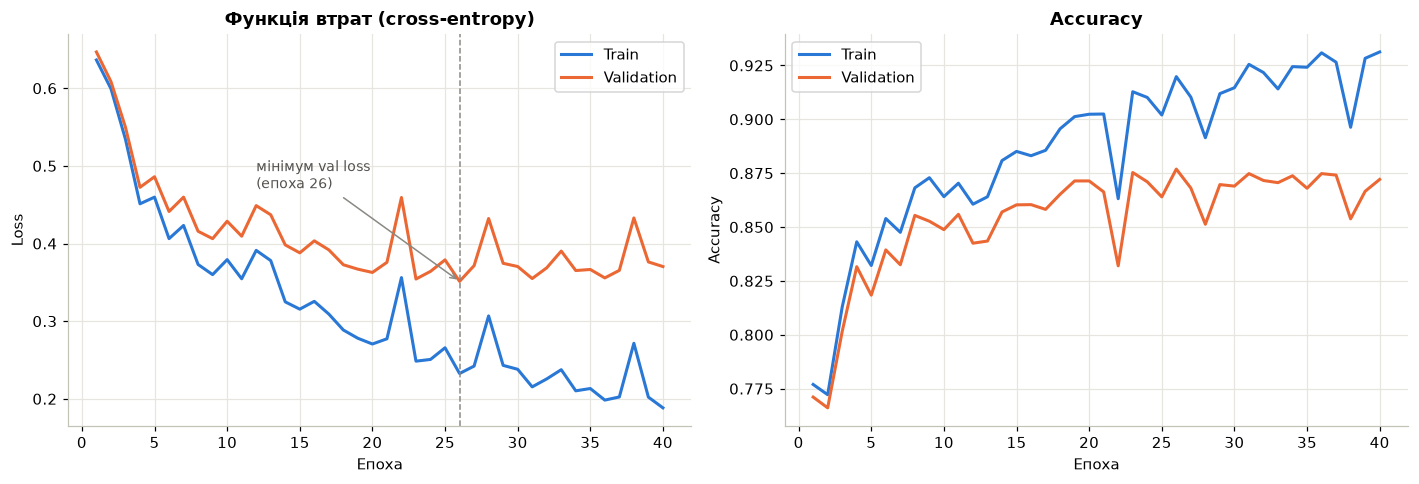

In [7]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for split, color in (("train", COLORS["blue"]), ("val", COLORS["orange"])):
    label = "Train" if split == "train" else "Validation"
    axes[0].plot(epochs_axis, baseline_history[f"{split}_loss"], color=color, lw=2, label=label)
    axes[1].plot(epochs_axis, baseline_history[f"{split}_acc"], color=color, lw=2, label=label)
best_epoch = int(baseline_history["val_loss"].argmin()) + 1
axes[0].axvline(best_epoch, color=COLORS["muted"], ls="--", lw=1)
axes[0].annotate(f"мінімум val loss\n(епоха {best_epoch})", xy=(best_epoch, baseline_history["val_loss"].min()),
                 xytext=(best_epoch - 14, baseline_history["val_loss"].min() + 0.12), color=COLORS["ink"], fontsize=9,
                 arrowprops={"arrowstyle": "->", "color": COLORS["muted"]})
axes[0].set(title="Функція втрат (cross-entropy)", xlabel="Епоха", ylabel="Loss")
axes[1].set(title="Accuracy", xlabel="Епоха", ylabel="Accuracy")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Коментар.** За перші ~5 епох втрати швидко падають на обох вибірках. Далі train loss продовжує знижуватися до 0.19, а validation loss досягає мінімуму 0.351 на **26-й епосі** і потім зростає до 0.370. Це класичне **перенавчання**: мережа з 242 тис. параметрів на 20 тис. прикладів починає запам'ятовувати Train. Accuracy розходиться так само: на останній епосі 0.931 на Train проти 0.872 на Validation. Середнє за останні 5 епох — 0.923 проти 0.868, тобто розрив 5.4 п.п. (процентного пункту).

Окремі «стрибки» (епохи 22, 28, 38) характерні для SGD з постійним кроком: один невдалий крок одночасно погіршує і Train, і Validation. Саме тому для порівнянь використовуємо середнє за останні 5 епох. Наявність перенавчання і є підставою досліджувати регуляризацію.

## 1.5 Збереження та відновлення ваг

`save_weights` зберігає у файл `.npz` (`numpy.savez`) усі матриці ваг, усі вектори зміщень і JSON-конфігурацію: архітектуру, метод і `seed` ініціалізації, параметри регуляризації. `load_weights` завантажує ваги в уже створений екземпляр, а `from_file` будує новий екземпляр за збереженою конфігурацією й завантажує в нього ваги.

**Перевірка за умовою:** зберігаємо навчену мережу → створюємо новий екземпляр з такою самою архітектурою (з **іншими** випадковими вагами) → завантажуємо ваги → подаємо однакові дані → порівнюємо ймовірності та класи. Критерій: $\max |P_{original} - P_{restored}| < 10^{-7}$.

In [8]:
weights_path = MODELS_DIR / "baseline_mlp.npz"
baseline.save_weights(weights_path)

with np.load(weights_path) as stored:
    display(pd.DataFrame([
        {"ключ": key, "форма": str(stored[key].shape), "тип": str(stored[key].dtype)} for key in stored.files
    ]))
    print("Конфігурація у файлі:", str(stored["config"]))

restored = NeuralNetwork(ARCHITECTURE, seed=SEED + 999)
before_load_diff = np.max(np.abs(baseline.predict_proba(X_val) - restored.predict_proba(X_val)))
restored.load_weights(weights_path)
P_original = baseline.predict_proba(X_val)
P_restored = restored.predict_proba(X_val)
max_difference = float(np.max(np.abs(P_original - P_restored)))
same_classes = bool(np.array_equal(P_original.argmax(axis=1), P_restored.argmax(axis=1)))

rebuilt = NeuralNetwork.from_file(weights_path)
rebuilt_difference = float(np.max(np.abs(P_original - rebuilt.predict_proba(X_val))))

display(pd.DataFrame([
    {"перевірка": "новий екземпляр до завантаження ваг", "max |ΔP|": before_load_diff, "класи збігаються": "—"},
    {"перевірка": "новий екземпляр + load_weights", "max |ΔP|": max_difference, "класи збігаються": same_classes},
    {"перевірка": "NeuralNetwork.from_file (архітектура з файлу)", "max |ΔP|": rebuilt_difference,
     "класи збігаються": bool(np.array_equal(P_original.argmax(axis=1), rebuilt.predict(X_val)))},
]).style.format({"max |ΔP|": "{:.2e}"}))
assert max_difference < 1e-7 and same_classes and rebuilt_difference < 1e-7
print(f"Відновлення коректне: max |P_original − P_restored| = {max_difference:.1e} < 1e-7, "
      f"розмір файлу {weights_path.stat().st_size / 1024:.0f} КБ")

,ключ,форма,тип
0,W_0,"(784, 256)",float32
1,W_1,"(256, 128)",float32
2,W_2,"(128, 64)",float32
3,W_3,"(64, 10)",float32
4,b_0,"(256,)",float32
5,b_1,"(128,)",float32
6,b_2,"(64,)",float32
7,b_3,"(10,)",float32
8,config,(),<U164


Конфігурація у файлі: {"layer_sizes": [784, 256, 128, 64, 10], "init": "he", "seed": 42, "dropout": 0.0, "l1": 0.0, "l2": 0.0, "weight_clip": null, "grad_clip": null, "dtype": "float32"}


,перевірка,max |ΔP|,класи збігаються
0,новий екземпляр до завантаження ваг,9.54e-01,—
1,новий екземпляр + load_weights,0.00e+00,True
2,NeuralNetwork.from_file (архітектура з файлу),0.00e+00,True


Відновлення коректне: max |P_original − P_restored| = 0.0e+00 < 1e-7, розмір файлу 951 КБ


**Коментар.** До завантаження новий екземпляр дає зовсім інші ймовірності, бо має власні випадкові ваги. Після `load_weights` різниця дорівнює нулю, і передбачені класи збігаються для всіх 10 000 об'єктів Validation. Ваги зберігаються у `float32` без втрати точності, тому відновлена мережа обчислює ті самі числа. `from_file` додатково показує, що конфігурації з файлу достатньо, щоб відтворити мережу без ручного задання архітектури.

# Блок 2. Дослідження впливу регуляризації

## 2.0 Діагностика: мертві нейрони, sparsity, розподіл ваг

- **Мертвий нейрон** — прихований нейрон, передактивація якого не додатна для жодного об'єкта Train: $\max_i Z^{(l)}_{ij} \le 0$. Перевіряємо на всіх 20 000 об'єктах Train у режимі inference, тобто з вимкненим Dropout, щоб випадково вимкнені нейрони не потрапили до мертвих.
- **Sparsity** (розрідженість) — частка ваг прихованих шарів ($W^{(1)}, W^{(2)}, W^{(3)}$) з $|W_{ij}| < 0.01$.
- **Розподіл ваг** — гістограми всіх ваг прихованих шарів.

Усі експерименти використовують ту саму архітектуру, початкові ваги, порядок батчів, $\eta$ і кількість епох, що й базова модель.

**Яку точність порівнюємо.** Навчання SGD з постійним кроком дає коливання валідаційної точності між сусідніми епохами (≈ ±1%). Тому, окрім значення **останньої епохи** (як вимагає умова), наводимо **середнє за останні 5 епох** і саме його використовуємо для порівнянь.

In [9]:
HIDDEN_SIZES = ARCHITECTURE[1:-1]
SPARSITY_THRESHOLD = 0.01


def dead_neurons(model, X):
    model.forward(X, training=False)
    return [int(np.sum(Z.max(axis=0) <= 0)) for Z in model.z_values[:-1]]


def hidden_weights(model):
    return np.concatenate([W.ravel() for W in model.weights[:-1]])


def diagnose(name, group, parameter, model, history):
    dead = dead_neurons(model, X_train)
    weights = hidden_weights(model)
    row = {
        "метод": name,
        "група": group,
        "параметр": parameter,
        "dead, %": 100 * sum(dead) / sum(HIDDEN_SIZES),
        "sparsity, %": 100 * float(np.mean(np.abs(weights) < SPARSITY_THRESHOLD)),
        "val acc (остання)": history["val_acc"][-1],
        "val acc (сер. 5)": history["val_acc"][-5:].mean(),
        "val loss (остання)": history["val_loss"][-1],
        "val loss (сер. 5)": history["val_loss"][-5:].mean(),
        "train acc (сер. 5)": history["train_acc"][-5:].mean(),
        "min val loss": history["val_loss"].min(),
        "max |W|": float(np.abs(weights).max()),
        "std W": float(weights.std()),
        "час, с": history["seconds"],
    }
    for layer, (count, size) in enumerate(zip(dead, HIDDEN_SIZES), start=1):
        row[f"dead h{layer}"] = f"{count}/{size} ({100 * count / size:.1f}%)"
    return row


experiments = {}


def run_experiment(name, group, parameter, **regularization):
    if name in experiments:
        return experiments[name]
    model = NeuralNetwork(ARCHITECTURE, **regularization)
    history = train(model, X_train, y_train, X_val, y_val)
    experiments[name] = {"model": model, "history": history, "row": diagnose(name, group, parameter, model, history)}
    return experiments[name]


experiments["Без регуляризації"] = {
    "model": baseline, "history": baseline_history,
    "row": diagnose("Без регуляризації", "baseline", "—", baseline, baseline_history),
}

LAYER_COLUMNS = ["dead h1", "dead h2", "dead h3"]
MAIN_COLUMNS = ["параметр", "dead, %", "sparsity, %", "val acc (остання)", "val acc (сер. 5)",
                "val loss (остання)", "train acc (сер. 5)", "max |W|"]


def show(names, columns=MAIN_COLUMNS):
    frame = pd.DataFrame([experiments[name]["row"] for name in names]).set_index("метод")
    return frame[columns].style.format({
        "dead, %": "{:.1f}", "sparsity, %": "{:.1f}", "val acc (остання)": "{:.4f}", "val acc (сер. 5)": "{:.4f}",
        "val loss (остання)": "{:.4f}", "val loss (сер. 5)": "{:.4f}", "train acc (сер. 5)": "{:.4f}", "max |W|": "{:.3f}",
    })


def weight_histograms(names, title, bins=np.linspace(-0.6, 0.6, 121), log=True):
    fig, axes = plt.subplots(1, len(names), figsize=(4.3 * len(names), 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    base_weights = hidden_weights(baseline)
    for ax, name in zip(axes, names):
        weights = hidden_weights(experiments[name]["model"])
        ax.hist(np.clip(initial_hidden_weights, bins[0], bins[-1]), bins=bins, histtype="step", color=COLORS["muted"],
                lw=1.2, label="He-ініціалізація")
        if name != "Без регуляризації":
            ax.hist(np.clip(base_weights, bins[0], bins[-1]), bins=bins, histtype="step", color=COLORS["blue"],
                    lw=1.2, label="без регуляризації")
        ax.hist(np.clip(weights, bins[0], bins[-1]), bins=bins, color=COLORS["orange"], alpha=0.55, label=name)
        ax.set(title=name, xlabel="значення ваги")
        if log:
            ax.set_yscale("log")
        ax.legend(fontsize=7, loc="upper right")
    axes[0].set_ylabel("кількість ваг" + (" (log)" if log else ""))
    fig.suptitle(title, y=1.03)
    plt.tight_layout()
    plt.show()


print("Частка ваг з |W| < 0.01 одразу після He-ініціалізації: "
      f"{100 * np.mean(np.abs(initial_hidden_weights) < SPARSITY_THRESHOLD):.1f}%")

Частка ваг з |W| < 0.01 одразу після He-ініціалізації: 14.5%


## 2.1 Базовий експеримент (без регуляризації)

,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556


Мертві нейрони базової моделі по шарах:

,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)


,mean,std,max |W|,"sparsity, %",std після He
шар,,,,,
W1 (784×256),0.0001,0.0526,0.2630,15.1457,0.0506
W2 (256×128),0.0022,0.0927,0.4066,8.9172,0.0880
W3 (128×64),0.0047,0.1358,0.5558,5.9082,0.1235
W4 (64×10),0.0017,0.2682,0.8568,2.6562,0.1772


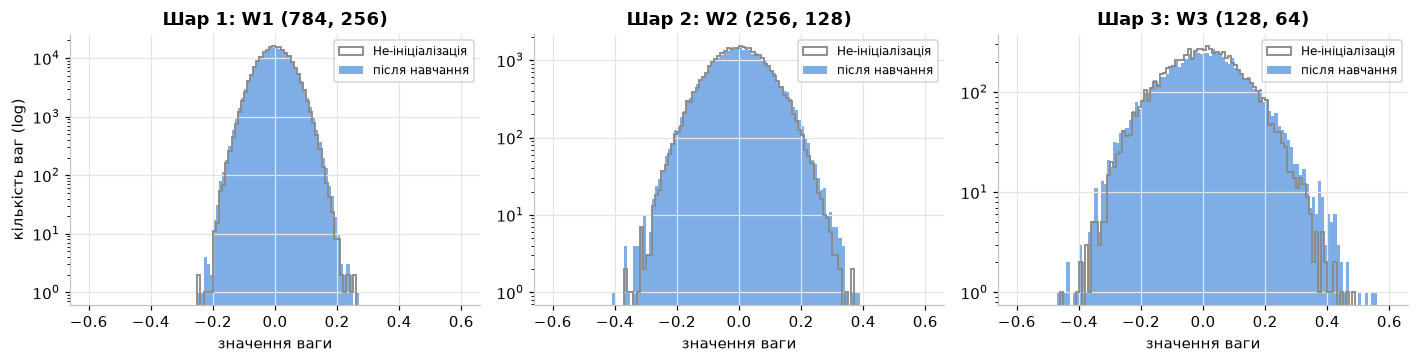

In [10]:
display(show(["Без регуляризації"]))
display(Markdown("Мертві нейрони базової моделі по шарах:"))
display(show(["Без регуляризації"], LAYER_COLUMNS))
display(pd.DataFrame([
    {"шар": f"W{l + 1} ({W.shape[0]}×{W.shape[1]})", "mean": W.mean(), "std": W.std(), "max |W|": np.abs(W).max(),
     "sparsity, %": 100 * np.mean(np.abs(W) < SPARSITY_THRESHOLD),
     "std після He": initial_model.weights[l].std()}
    for l, W in enumerate(baseline.weights)
]).set_index("шар").round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for l, ax in enumerate(axes):
    bins = np.linspace(-0.6, 0.6, 121)
    ax.hist(initial_model.weights[l].ravel(), bins=bins, histtype="step", color=COLORS["muted"], lw=1.2, label="He-ініціалізація")
    ax.hist(baseline.weights[l].ravel(), bins=bins, color=COLORS["blue"], alpha=0.6, label="після навчання")
    ax.set(title=f"Шар {l + 1}: W{l + 1} {baseline.weights[l].shape}", xlabel="значення ваги", yscale="log")
    ax.legend(fontsize=8)
axes[0].set_ylabel("кількість ваг (log)")
plt.tight_layout()
plt.show()

**Коментар до базового експерименту.**

- **Мертві нейрони:** лише 1 з 64 нейронів третього шару (0.2% від усіх 448 прихованих нейронів). У перших двох шарах мертвих немає. He-ініціалізація разом з помірним кроком майже не створює мертвих нейронів.
- **Розподіл ваг** після навчання дуже близький до початкового He-розподілу. Стандартне відхилення трохи зросло: W1 — з 0.0506 до 0.0526, W3 — з 0.1235 до 0.1358, вихідний W4 — з 0.177 до 0.268. Хвости подовжилися, максимальна $|W|$ прихованих шарів — 0.556. Найменше змінюється перший шар. Пікселі біля країв зображення майже завжди дорівнюють 0, тому відповідні рядки $W^{(1)}$ отримують нульовий градієнт ($A^{(0)T}\delta$) і лишаються на початкових значеннях.
- **Sparsity 14.0% майже повністю «успадкована» від ініціалізації** (після He — 14.5%). Нормальний розподіл з $\sigma = 0.05$ сам по собі має ≈ 15% маси в $|w| < 0.01$. Отже, ≈ 14% — це **фоновий рівень** розрідженості, а не ефект навчання, і саме з ним порівнюємо методи далі.

## 2.2 L2-регуляризація

$L = L_{CE} + \frac{\lambda_2}{2} \sum_l \lVert W^{(l)} \rVert_2^2$, оновлення $W \leftarrow W - \eta(\nabla_W L_{CE} + \lambda_2 W)$. Досліджуємо $\lambda_2 \in \{10^{-4}, 10^{-3}, 10^{-2}\}$.

,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
L2 λ₂=0.0001,λ₂ = 0.0001,0.2,14.3,0.8729,0.8677,0.3667,0.9201,0.547
L2 λ₂=0.001,λ₂ = 0.001,0.4,17.6,0.8740,0.8658,0.3606,0.9089,0.469
L2 λ₂=0.01,λ₂ = 0.01,2.7,71.7,0.8539,0.8420,0.4393,0.8500,0.317


,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L2 λ₂=0.0001,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L2 λ₂=0.001,0/256 (0.0%),0/128 (0.0%),2/64 (3.1%)
L2 λ₂=0.01,0/256 (0.0%),6/128 (4.7%),6/64 (9.4%)


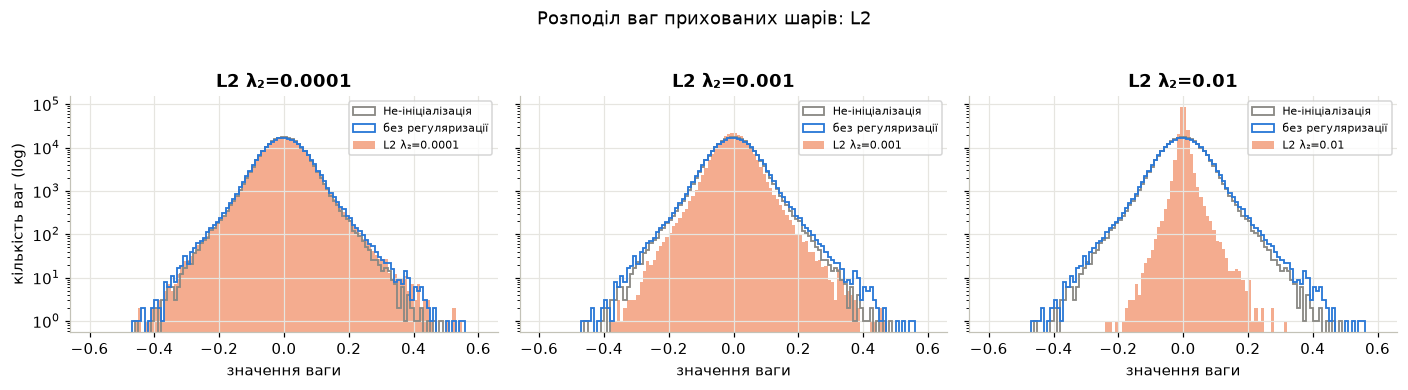

In [11]:
L2_VALUES = [1e-4, 1e-3, 1e-2]
for value in L2_VALUES:
    run_experiment(f"L2 λ₂={value:g}", "L2", f"λ₂ = {value:g}", l2=value)
l2_names = ["Без регуляризації"] + [f"L2 λ₂={value:g}" for value in L2_VALUES]
display(show(l2_names))
display(show(l2_names, LAYER_COLUMNS))
weight_histograms(l2_names[1:], "Розподіл ваг прихованих шарів: L2")

**Коментар до L2.**

- **$\lambda_2 = 10^{-4}$** майже нічого не змінює: val accuracy 0.8677 проти 0.8683, розподіл ваг і sparsity (14.3%) — як у базовій моделі. Штраф занадто слабкий порівняно з градієнтом крос-ентропії.
- **$\lambda_2 = 10^{-3}$** помітно стискає ваги: std 0.064 → 0.051, $\max|W|$ 0.556 → 0.469, sparsity 17.6%. Розрив train − val зменшився з 5.4 до 4.3 п.п., а val loss останньої епохи (0.361) нижчий, ніж у базовій (0.370). Середня val accuracy 0.8658 — у межах шуму від базової. Перенавчання зменшилось, але точність не зросла.
- **$\lambda_2 = 10^{-2}$** — надмірна регуляризація. Ваги стиснуті до std 0.014, 71.7% з них $|W| < 0.01$, $\max|W| = 0.317$. Розрив train − val лише 0.8 п.п., але **за рахунок падіння train accuracy до 0.850**: val accuracy 0.842, тобто недонавчання. З'являються мертві нейрони: 6 у h2 і 6 у h3 (2.7%). Ймовірна причина: коли ваги дуже малі, передактивація визначається переважно зміщенням, і нейрони з від'ємним зміщенням перестають активуватися на всіх об'єктах.
- **Характер дії L2.** Оновлення $W \leftarrow W(1 - \eta\lambda_2) - \eta\nabla L_{CE}$ зменшує кожну вагу **пропорційно її величині**. Розподіл стає вужчим, але лишається дзвоноподібним, без піку в нулі. Навіть при $\lambda_2 = 10^{-2}$ лише 10% ваг $|W| < 0.001$. Висока «sparsity» тут означає загальне стискання ваг, а не точні нулі.

## 2.3 L1-регуляризація

$L = L_{CE} + \lambda_1 \sum_l \lVert W^{(l)} \rVert_1$, градієнт штрафу $\lambda_1 \operatorname{sign}(W)$. У нулі використовуємо субградієнт 0 (`np.sign(0) = 0`). Досліджуємо $\lambda_1 \in \{10^{-5}, 10^{-4}, 10^{-3}\}$.

,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
L1 λ₁=1e-05,λ₁ = 1e-05,0.2,17.0,0.8732,0.8658,0.3710,0.9173,0.557
L1 λ₁=0.0001,λ₁ = 0.0001,0.9,44.9,0.8725,0.8644,0.3657,0.9039,0.570
L1 λ₁=0.001,λ₁ = 0.001,21.2,98.6,0.8264,0.8141,0.4939,0.8190,0.952


,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L1 λ₁=1e-05,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L1 λ₁=0.0001,0/256 (0.0%),0/128 (0.0%),4/64 (6.2%)
L1 λ₁=0.001,60/256 (23.4%),28/128 (21.9%),7/64 (10.9%)


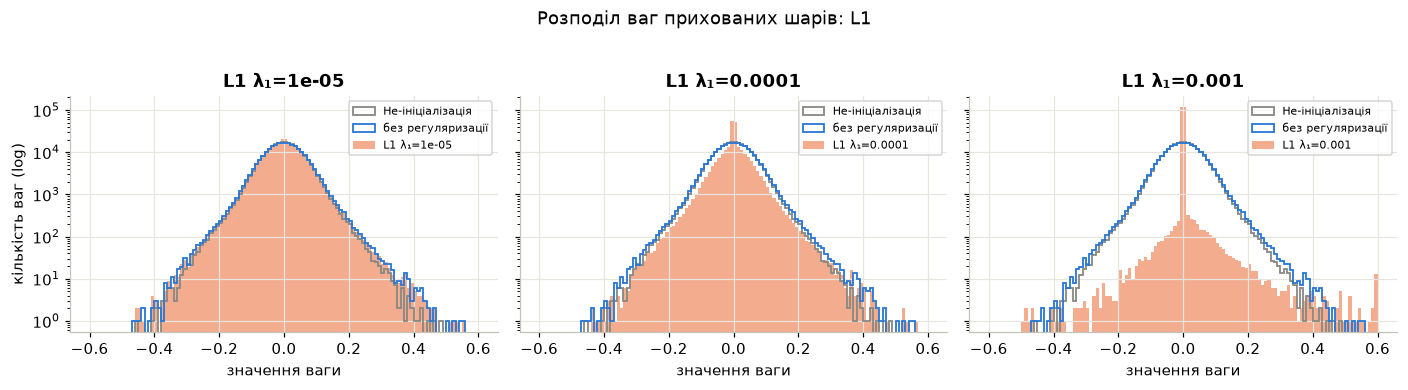

In [12]:
L1_VALUES = [1e-5, 1e-4, 1e-3]
for value in L1_VALUES:
    run_experiment(f"L1 λ₁={value:g}", "L1", f"λ₁ = {value:g}", l1=value)
l1_names = ["Без регуляризації"] + [f"L1 λ₁={value:g}" for value in L1_VALUES]
display(show(l1_names))
display(show(l1_names, LAYER_COLUMNS))
weight_histograms(l1_names[1:], "Розподіл ваг прихованих шарів: L1")

**Коментар до L1.**

- **$\lambda_1 = 10^{-5}$:** sparsity 17.0%, частка ваг $|W| < 0.001$ зросла з 1.4% до 2.9%. На гістограмі вже видно вузький пік у нулі, а точність така сама, як у базової моделі.
- **$\lambda_1 = 10^{-4}$:** **44.9% ваг майже нульові**, з них 30.9% мають $|W| < 0.001$. При цьому val accuracy 0.8644, на останній епосі 0.8725, а val loss 0.366 навіть нижчий за базовий. Майже половину зв'язків мережа «вимкнула» без втрати якості, тобто модель має велику надлишковість. Мертвих нейронів 0.9% (4 з 64 у h3).
- **$\lambda_1 = 10^{-3}$:** **98.6% ваг майже нульові** (97.4% — $|W| < 0.001$). Мертвих нейронів 21.2%: 60 з 256 у h1, 28 з 128 у h2, 7 з 64 у h3. Якщо всі вхідні ваги нейрона занулено, його передактивація дорівнює зміщенню, і при зміщенні $\le 0$ нейрон мертвий. Точність падає до 0.814 разом з train accuracy (0.819) — це недонавчання. Небагато ваг, що вижили, навпаки **виросли** до $\max|W| = 0.952$ (у базовій 0.556): мережа компенсує втрачені зв'язки кількома сильними.
- **Чому L1 дає нулі, а L2 — ні.** Субградієнт $\lambda_1\operatorname{sign}(W)$ тягне кожну вагу до нуля на **сталу** величину $\eta\lambda_1$ за крок, незалежно від її розміру. Малі ваги, для яких градієнт крос-ентропії слабший за цей тиск, доходять до нуля й коливаються навколо нього з амплітудою $\eta\lambda_1 = 2 \cdot 10^{-5}$. Звідси різкий пік на гістограмі й «важкі» хвости.

## 2.4 Dropout

Inverted Dropout після ReLU кожного прихованого шару, $p \in \{0.1, 0.3, 0.5\}$ — ймовірність вимкнення нейрона. Під час оцінювання й діагностики мертвих нейронів Dropout вимкнено. Окремо навчаємо й $p = 0.2$, щоб чесно порівняти його з комбінацією L2 + Dropout 0.2 у розділі 2.7.

,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
Dropout 0.1,p = 0.1,0.0,14.0,0.8796,0.8754,0.3342,0.9158,0.574
Dropout 0.3,p = 0.3,0.0,14.0,0.8772,0.8750,0.3551,0.9041,0.533
Dropout 0.5,p = 0.5,0.0,14.0,0.8578,0.8597,0.4152,0.8790,0.494


,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
Dropout 0.1,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)
Dropout 0.3,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)
Dropout 0.5,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)


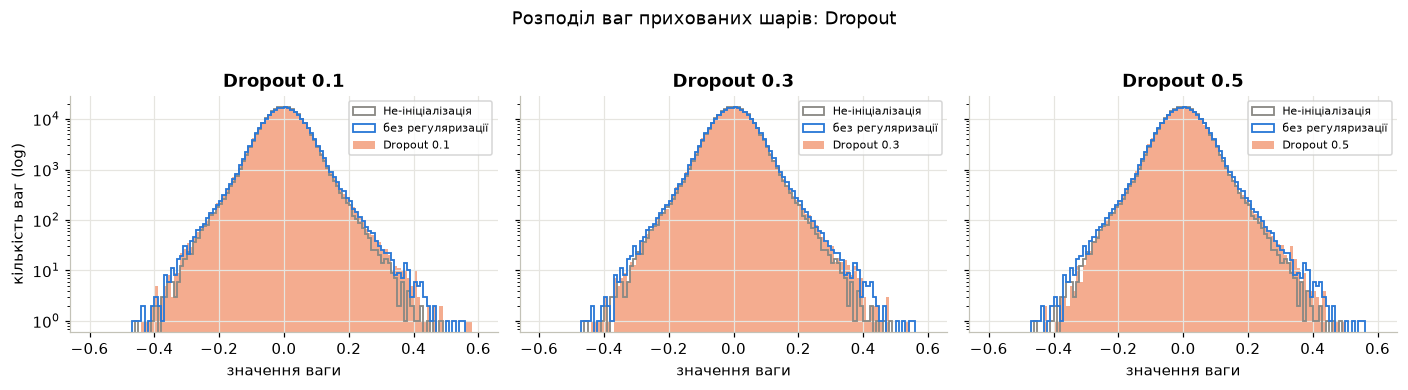

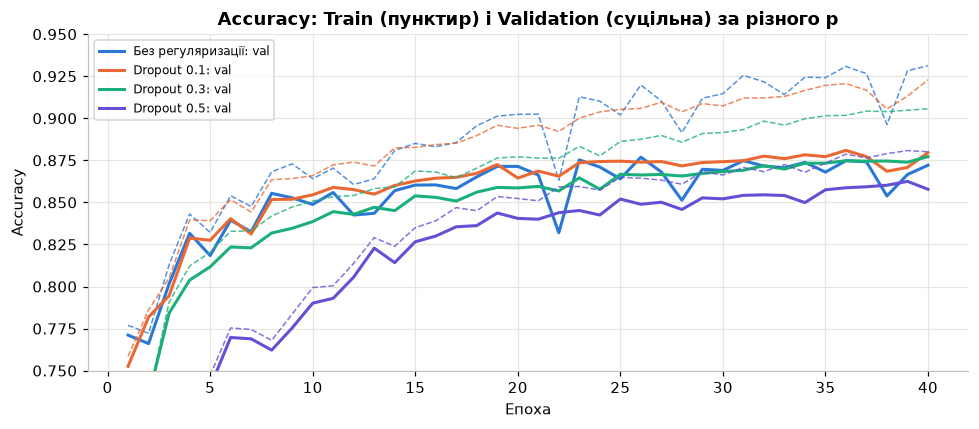

In [13]:
DROPOUT_VALUES = [0.1, 0.3, 0.5]
for value in DROPOUT_VALUES + [0.2]:
    run_experiment(f"Dropout {value:g}", "Dropout", f"p = {value:g}", dropout=value)
dropout_names = ["Без регуляризації"] + [f"Dropout {value:g}" for value in DROPOUT_VALUES]
display(show(dropout_names))
display(show(dropout_names, LAYER_COLUMNS))
weight_histograms(dropout_names[1:], "Розподіл ваг прихованих шарів: Dropout")

fig, ax = plt.subplots(figsize=(9, 4))
for name, color in zip(dropout_names, [COLORS["blue"], COLORS["orange"], COLORS["aqua"], COLORS["violet"]]):
    history = experiments[name]["history"]
    ax.plot(epochs_axis, history["val_acc"], color=color, lw=2, label=f"{name}: val")
    ax.plot(epochs_axis, history["train_acc"], color=color, lw=1, ls="--", alpha=0.8)
ax.set(title="Accuracy: Train (пунктир) і Validation (суцільна) за різного p", xlabel="Епоха", ylabel="Accuracy", ylim=(0.75, 0.95))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Коментар до Dropout.**

- **Точність:** p = 0.1 → 0.8754, p = 0.2 → **0.8773** (найкращий окремий метод), p = 0.3 → 0.8750, p = 0.5 → 0.8597 — гірше за базову 0.8683. Найменший val loss має p = 0.1 (0.334 проти 0.370 у базовій).
- **Перенавчання** зменшується монотонно зі зростанням p: розрив train − val 4.0 → 3.6 → 2.9 → 1.9 п.п. (у базовій 5.4). На графіку пунктирні train-криві тим нижчі, чим більше p.
- **Мертвих нейронів 0** при всіх p: навіть єдиний мертвий нейрон базової моделі не з'являється. Ймовірна причина в тому, що випадкові маски постійно змінюють, які нейрони отримують градієнт. Мережа не може покладатися на окремі нейрони й «розподіляє» корисні ознаки між багатьма. Діагностику робили з вимкненим Dropout, тож випадково вимкнені нейрони до мертвих не потрапили.
- **Sparsity (≈ 14%) і гістограми ваг не змінились:** Dropout діє на активації, а не на ваги, і не додає штрафу до функції втрат.
- **Чому більше p не означає краще.** При p = 0.5 на кожному кроці працює лише половина нейронів, у шарі h3 це в середньому ~32 з 64. Градієнт стає дуже шумним, а ефективна місткість мережі під час навчання різко падає. За 40 епох модель не встигає навчитися: train accuracy лише 0.879. Регуляризація переходить у недонавчання. Оптимальне p тут невелике (0.1–0.3), бо перенавчання базової моделі помірне.

## 2.5 Weight clipping

Після кожного кроку $W \leftarrow \operatorname{clip}(W, -1, 1)$ — обов'язковий варіант умови. Як видно з базової моделі, без обмеження $\max|W|$ значно менше за 1. Тому межа $\pm1$ навряд чи буде досягнута, і щоб показати сам механізм, додатково навчаємо мережу з жорсткішою межею $\pm 0.1$.

,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
Weight clipping ±1,c_w = 1,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
Weight clipping ±0.1,c_w = 0.1,0.2,13.9,0.8627,0.8533,0.4000,0.8675,0.100


,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
Weight clipping ±1,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
Weight clipping ±0.1,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)


,межа,рівно на межі,"рівно на межі, %",на −межі / +межі,у смузі 0.001 від межі,"у смузі 0.001, %",на межі по шарах W1 / W2 / W3
метод,,,,,,,
Без регуляризації,±1,0,0.000,0 / 0,0,0.000,0 (0.0%) / 0 (0.0%) / 0 (0.0%)
Weight clipping ±1,±1,0,0.000,0 / 0,0,0.000,0 (0.0%) / 0 (0.0%) / 0 (0.0%)
Weight clipping ±0.1,±0.1,1706,0.706,987 / 719,18211,7.536,594 (0.3%) / 677 (2.1%) / 435 (5.3%)


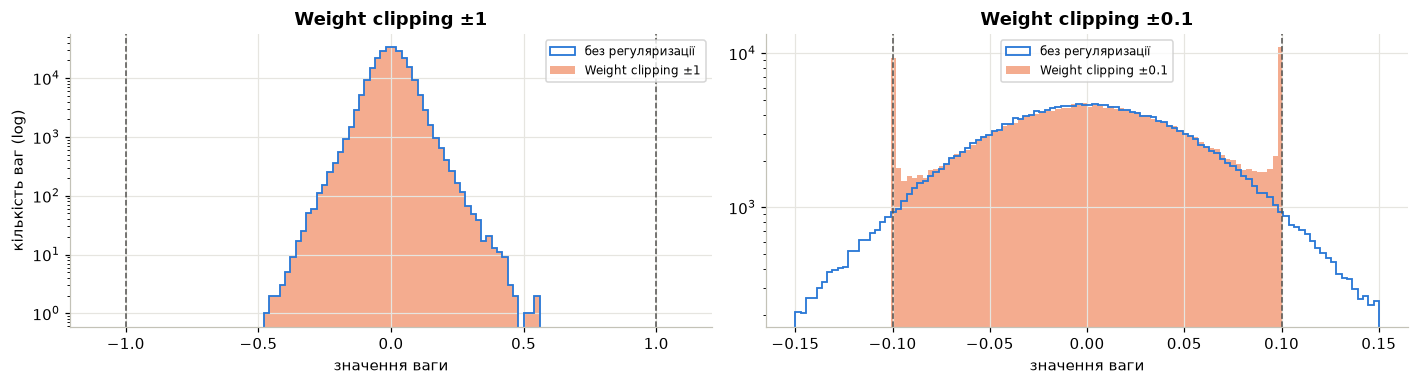

In [14]:
for bound in (1.0, 0.1):
    run_experiment(f"Weight clipping ±{bound:g}", "Weight clipping", f"c_w = {bound:g}", weight_clip=bound)
clip_names = ["Без регуляризації", "Weight clipping ±1", "Weight clipping ±0.1"]
display(show(clip_names))
display(show(clip_names, LAYER_COLUMNS))

bound_rows = []
for name, bound in (("Без регуляризації", 1.0), ("Weight clipping ±1", 1.0), ("Weight clipping ±0.1", 0.1)):
    model = experiments[name]["model"]
    weights = hidden_weights(model)
    at_bounds = np.abs(weights) >= bound - 1e-6
    near_bounds = np.abs(weights) >= bound - 1e-3
    bound_rows.append({
        "метод": name, "межа": f"±{bound:g}",
        "рівно на межі": int(at_bounds.sum()), "рівно на межі, %": 100 * at_bounds.mean(),
        "на −межі / +межі": f"{int((weights <= -bound + 1e-6).sum())} / {int((weights >= bound - 1e-6).sum())}",
        "у смузі 0.001 від межі": int(near_bounds.sum()), "у смузі 0.001, %": 100 * near_bounds.mean(),
        "на межі по шарах W1 / W2 / W3": " / ".join(
            f"{int((np.abs(W) >= bound - 1e-6).sum())} ({100 * np.mean(np.abs(W) >= bound - 1e-6):.1f}%)"
            for W in model.weights[:-1]),
    })
display(pd.DataFrame(bound_rows).set_index("метод").round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (name, limit) in zip(axes, (("Weight clipping ±1", 1.1), ("Weight clipping ±0.1", 0.15))):
    bins = np.linspace(-limit, limit, 111)
    ax.hist(hidden_weights(baseline), bins=bins, histtype="step", color=COLORS["blue"], lw=1.2, label="без регуляризації")
    ax.hist(hidden_weights(experiments[name]["model"]), bins=bins, color=COLORS["orange"], alpha=0.55, label=name)
    bound = 1.0 if "±1" in name else 0.1
    for edge in (-bound, bound):
        ax.axvline(edge, color=COLORS["ink"], ls="--", lw=1)
    ax.set(title=name, xlabel="значення ваги", yscale="log")
    ax.legend(fontsize=8)
axes[0].set_ylabel("кількість ваг (log)")
plt.tight_layout()
plt.show()

**Коментар до weight clipping.**

- **Межа ±1 (варіант умови) неактивна.** Жодна вага не досягла меж ±1, і всі метрики збіглися з базовою моделлю до останнього знака. Найбільша вага прихованих шарів дорівнює 0.556, а He-ініціалізація дає $\sigma \approx 0.05$–$0.12$, тож при кроці 0.02 ваги не підходять навіть близько до ±1. Таке обмеження стало б важливим лише за «вибуху» ваг: при великому learning rate, без нормалізації входів або в дуже глибокій мережі.
- **Межа ±0.1** вже активна. **Рівно на межі** опиняються 1 706 ваг (0.7%), а **в смузі 0.001 від межі** — значно більше (див. таблицю). На гістограмі це видно як різкі піки біля ±0.1. Механізм такий: вага, яку градієнт штовхає назовні, обрізається до межі, наступний крок трохи зсуває її всередину, і вона знову впирається в межу. Найчастіше на межі опиняються ваги глибших шарів: у W3 частка найбільша, бо там навіть He-ініціалізація дає $\sigma = 0.125 > 0.1$.
- **Наслідок для якості.** Val accuracy 0.8533 (−1.5 п.п.), train accuracy 0.8675. Розрив train − val малий (1.4 п.п.), але через **недонавчання**, а не кращу узагальнювальну здатність. Жорстке обмеження відрізає частину простору параметрів. Якщо оптимальні ваги мають $|w| > 0.1$, градієнтний спуск з проєкцією на «коробку» $[-c, c]$ може знайти лише найкращу точку **всередині** коробки, а не справжній оптимум.
- **Sparsity і мертві нейрони не змінились** (13.9%, 1 нейрон): обмеження зверху не впливає на малі ваги.

## 2.6 Gradient clipping

Градієнт усієї мережі масштабується за глобальною L2-нормою: $g \leftarrow g \cdot \min(1, c / \lVert g \rVert_2)$. Щоб пороги були змістовними, спершу дивимося на типові норми градієнта базової моделі, а потім беремо $c \in \{0.5, 1, 2\}$.

,глобальна норма градієнта (baseline)
медіана,2.321
90-й перцентиль,3.383
99-й перцентиль,4.697
максимум,7.439


,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
Gradient clipping c=0.5,c = 0.5,1.1,14.4,0.8574,0.8565,0.4068,0.8756,0.517
Gradient clipping c=1,c = 1,0.7,14.3,0.8675,0.8666,0.3881,0.8948,0.517
Gradient clipping c=2,c = 2,0.4,14.0,0.8704,0.8708,0.3795,0.9192,0.543


,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
Gradient clipping c=0.5,0/256 (0.0%),0/128 (0.0%),5/64 (7.8%)
Gradient clipping c=1,0/256 (0.0%),0/128 (0.0%),3/64 (4.7%)
Gradient clipping c=2,0/256 (0.0%),0/128 (0.0%),2/64 (3.1%)


,"частка обрізаних кроків, %",std batch loss (ост. 5 епох),std val loss по епохах (ост. 10),max норма градієнта
метод,,,,
Без регуляризації,0.0000,0.0677,0.0217,7.4392
Gradient clipping c=0.5,100.0000,0.0926,0.0062,9.4516
Gradient clipping c=1,99.9601,0.0850,0.0056,10.1273
Gradient clipping c=2,81.0543,0.0738,0.0108,8.8988


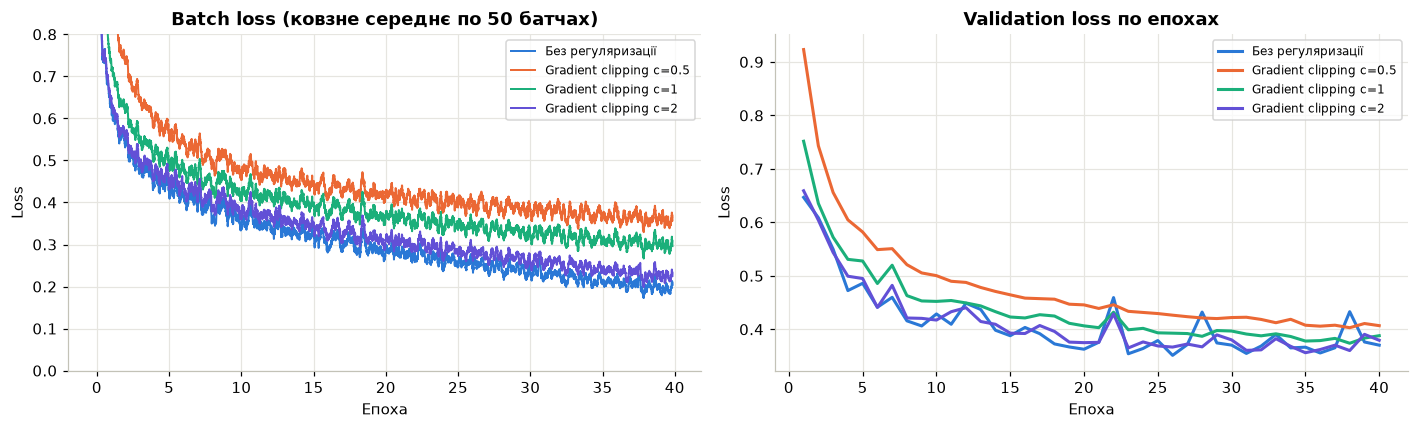

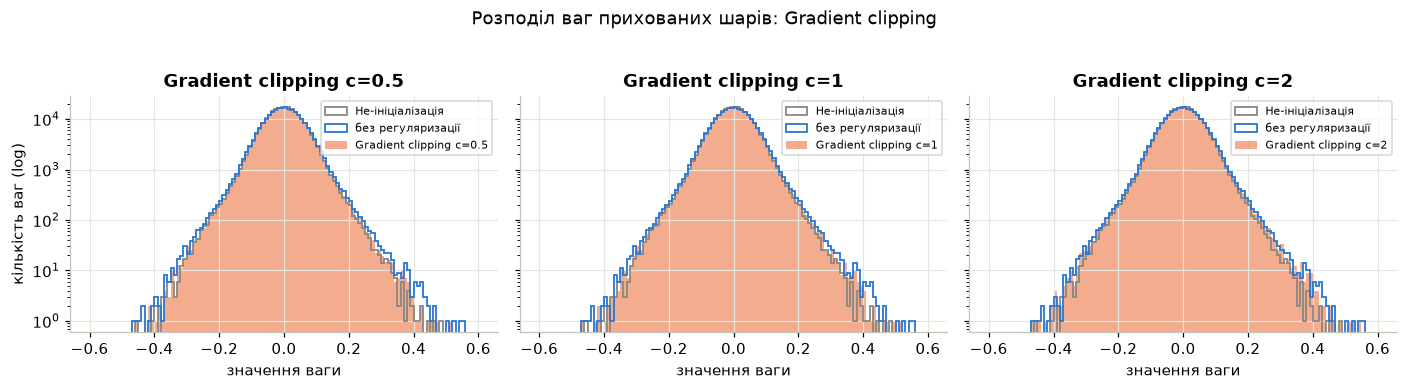

In [15]:
base_norms = baseline_history["grad_norms"]
display(pd.Series({
    "медіана": np.median(base_norms), "90-й перцентиль": np.percentile(base_norms, 90),
    "99-й перцентиль": np.percentile(base_norms, 99), "максимум": base_norms.max(),
}, name="глобальна норма градієнта (baseline)").round(3).to_frame())

GRAD_CLIP_VALUES = [0.5, 1.0, 2.0]
for value in GRAD_CLIP_VALUES:
    run_experiment(f"Gradient clipping c={value:g}", "Gradient clipping", f"c = {value:g}", grad_clip=value)
gc_names = ["Без регуляризації"] + [f"Gradient clipping c={value:g}" for value in GRAD_CLIP_VALUES]
display(show(gc_names))
display(show(gc_names, LAYER_COLUMNS))


def batch_loss_std(history, last_epochs=5):
    steps_per_epoch = len(history["batch_losses"]) // EPOCHS
    return float(history["batch_losses"][-last_epochs * steps_per_epoch:].std())


display(pd.DataFrame([{
    "метод": name,
    "частка обрізаних кроків, %": 100 * experiments[name]["history"]["clipped_share"],
    "std batch loss (ост. 5 епох)": batch_loss_std(experiments[name]["history"]),
    "std val loss по епохах (ост. 10)": experiments[name]["history"]["val_loss"][-10:].std(),
    "max норма градієнта": experiments[name]["history"]["grad_norms"].max(),
} for name in gc_names]).set_index("метод").round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
window = 50
for name, color in zip(gc_names, [COLORS["blue"], COLORS["orange"], COLORS["aqua"], COLORS["violet"]]):
    history = experiments[name]["history"]
    smoothed = np.convolve(history["batch_losses"], np.ones(window) / window, mode="valid")
    axes[0].plot(np.arange(len(smoothed)) / (len(history["batch_losses"]) / EPOCHS), smoothed, color=color, lw=1.3, label=name)
    axes[1].plot(epochs_axis, history["val_loss"], color=color, lw=2, label=name)
axes[0].set(title=f"Batch loss (ковзне середнє по {window} батчах)", xlabel="Епоха", ylabel="Loss", ylim=(0, 0.8))
axes[1].set(title="Validation loss по епохах", xlabel="Епоха", ylabel="Loss")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
weight_histograms(gc_names[1:], "Розподіл ваг прихованих шарів: Gradient clipping")

**Коментар до gradient clipping.**

- **Пороги відносно реальних норм.** Глобальна норма градієнта базової моделі має медіану 2.32, 99-й перцентиль 4.70 і максимум 7.44. Тому $c = 0.5$ і $c = 1$ обрізають майже **кожен** крок (100% і 99.96%), а $c = 2$ — 81% кроків.
- **Що це означає.** Коли обрізано кожен крок, оновлення має вигляд $\eta c \cdot g / \lVert g \rVert$. Напрям лишається напрямом градієнта, але довжина кроку стала. Фактично це **менший learning rate**: при $c = 0.5$ крок приблизно в $2.32 / 0.5 \approx 4.6$ раза коротший за типовий. Тому мережа навчається повільніше. Train accuracy 0.876 ($c = 0.5$) і 0.895 ($c = 1$) проти 0.923 у базовій, val accuracy 0.8565 і 0.8666. М'якший поріг $c = 2$ дає 0.8708 — на рівні базової, з трохи меншим розривом (4.8 п.п.).
- **Стабільність втрат** помітно краща. Стандартне відхилення val loss за останні 10 епох — 0.006 ($c = 0.5$), 0.006 ($c = 1$) і 0.011 ($c = 2$) проти 0.022 у базовій моделі. Стрибки базової кривої на епохах 22, 28 і 38 зникають або зменшуються, бо великі кроки обмежено. Вищий розкид batch loss при сильному clipping пояснюється вищим рівнем самих втрат (модель менше навчена), а не нестабільністю.
- **Розподіл ваг і sparsity** (14.0–14.4%) майже не змінились. На відміну від weight clipping, тут обмежуються **кроки**, а не самі ваги, тому піків біля меж немає. Кількість мертвих нейронів трохи зросла (до 5 з 64 у h3 при $c = 0.5$). Це відмінність у кілька нейронів без очевидного механізму, ймовірно, наслідок іншої траєкторії навчання.
- **Висновок.** У цій мережі градієнти не «вибухають», тож головний ефект clipping — зменшення ефективного кроку й згладжування втрат, а не регуляризація.

## 2.7 Комбінована регуляризація: L2 + Dropout 0.2

Обов'язкова комбінація умови: $L = L_{CE} + \frac{\lambda_2}{2}\sum \lVert W \rVert_2^2$ разом із Dropout $p = 0.2$. Навчаємо два варіанти:

1. $\lambda_2$ з розділу 2.2, що дав найкращу середню валідаційну точність;
2. відчутно сильніше $\lambda_2$, щоб перевірити, чи дасть поєднання двох помітних регуляризаторів синергію або, навпаки, надмірне обмеження моделі.

Кожну комбінацію порівнюємо з окремими L2 та Dropout 0.2 з тими самими параметрами.

Варіант 1: λ₂ = 0.0001 (найкраща середня val accuracy серед L2); варіант 2: λ₂ = 0.001


,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),train acc (сер. 5),max |W|
метод,,,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703,0.9226,0.556
L2 λ₂=0.0001,λ₂ = 0.0001,0.2,14.3,0.8729,0.8677,0.3667,0.9201,0.547
L2 λ₂=0.001,λ₂ = 0.001,0.4,17.6,0.8740,0.8658,0.3606,0.9089,0.469
Dropout 0.2,p = 0.2,0.0,14.1,0.8821,0.8773,0.3436,0.9128,0.544
L2 λ₂=0.0001 + Dropout 0.2,"λ₂ = 0.0001, p = 0.2",0.0,14.4,0.8818,0.8779,0.3423,0.9127,0.535
L2 λ₂=0.001 + Dropout 0.2,"λ₂ = 0.001, p = 0.2",0.0,17.7,0.8802,0.8746,0.3405,0.9062,0.459


,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L2 λ₂=0.0001,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L2 λ₂=0.001,0/256 (0.0%),0/128 (0.0%),2/64 (3.1%)
Dropout 0.2,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)
L2 λ₂=0.0001 + Dropout 0.2,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)
L2 λ₂=0.001 + Dropout 0.2,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)


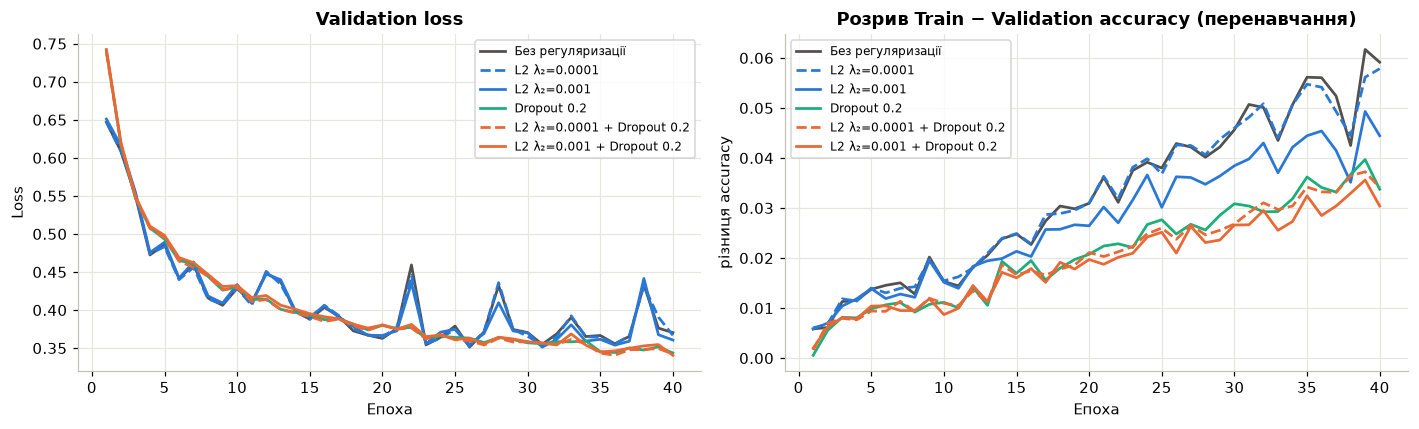

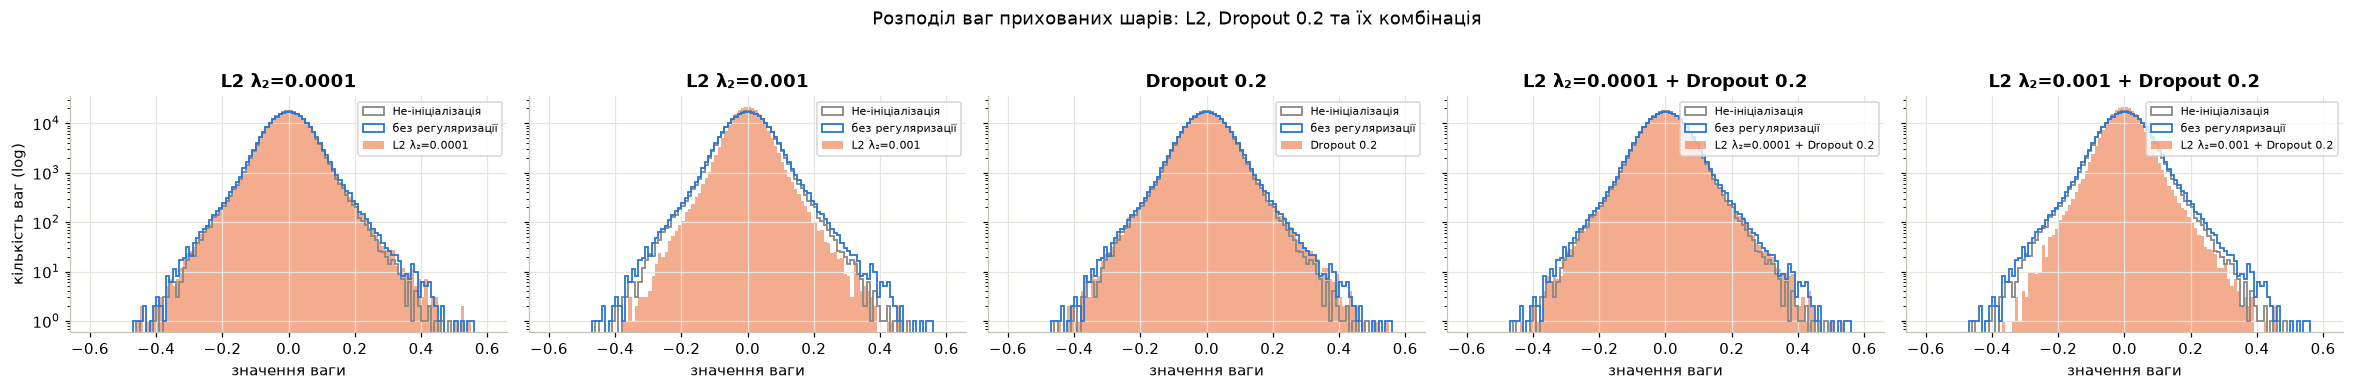

In [16]:
best_l2_name = max((f"L2 λ₂={value:g}" for value in L2_VALUES), key=lambda name: experiments[name]["row"]["val acc (сер. 5)"])
best_l2 = experiments[best_l2_name]["model"].l2
COMBO_NAME = f"L2 λ₂={best_l2:g} + Dropout 0.2"
run_experiment(COMBO_NAME, "L2 + Dropout", f"λ₂ = {best_l2:g}, p = 0.2", l2=best_l2, dropout=0.2)
STRONG_L2 = 1e-3 if best_l2 != 1e-3 else 1e-2
STRONG_COMBO_NAME = f"L2 λ₂={STRONG_L2:g} + Dropout 0.2"
run_experiment(STRONG_COMBO_NAME, "L2 + Dropout", f"λ₂ = {STRONG_L2:g}, p = 0.2", l2=STRONG_L2, dropout=0.2)
combo_names = ["Без регуляризації", best_l2_name, f"L2 λ₂={STRONG_L2:g}", "Dropout 0.2", COMBO_NAME, STRONG_COMBO_NAME]
print(f"Варіант 1: λ₂ = {best_l2:g} (найкраща середня val accuracy серед L2); варіант 2: λ₂ = {STRONG_L2:g}")
display(show(combo_names))
display(show(combo_names, LAYER_COLUMNS))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
combo_styles = [(COLORS["ink"], "-"), (COLORS["blue"], "--"), (COLORS["blue"], "-"), (COLORS["aqua"], "-"),
                (COLORS["orange"], "--"), (COLORS["orange"], "-")]
for name, (color, line_style) in zip(combo_names, combo_styles):
    history = experiments[name]["history"]
    axes[0].plot(epochs_axis, history["val_loss"], color=color, ls=line_style, lw=1.8, label=name)
    axes[1].plot(epochs_axis, history["train_acc"] - history["val_acc"], color=color, ls=line_style, lw=1.8, label=name)
axes[0].set(title="Validation loss", xlabel="Епоха", ylabel="Loss")
axes[1].set(title="Розрив Train − Validation accuracy (перенавчання)", xlabel="Епоха", ylabel="різниця accuracy")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
weight_histograms(combo_names[1:], "Розподіл ваг прихованих шарів: L2, Dropout 0.2 та їх комбінація")

**Коментар до комбінованої регуляризації.**

| | val acc (сер. 5) | val loss (остання) | розрив train − val | sparsity | dead |
|---|---|---|---|---|---|
| L2 $10^{-4}$ окремо | 0.8677 | 0.367 | 5.2 п.п. | 14.3% | 0.2% |
| L2 $10^{-3}$ окремо | 0.8658 | 0.361 | 4.3 п.п. | 17.6% | 0.4% |
| Dropout 0.2 окремо | 0.8773 | 0.344 | 3.6 п.п. | 14.1% | 0% |
| L2 $10^{-4}$ + Dropout 0.2 | **0.8779** | 0.342 | 3.5 п.п. | 14.4% | 0% |
| L2 $10^{-3}$ + Dropout 0.2 | 0.8746 | **0.341** | **3.2 п.п.** | 17.7% | 0% |

- **Чи покращилась точність?** Лише формально. Комбінація зі слабким L2 ($10^{-4}$) дає найвищу середню val accuracy серед усіх 18 експериментів (0.8779), але це +0.06 п.п. до чистого Dropout 0.2, тобто в межах шуму. Таке L2 занадто слабке, тож комбінація ≈ Dropout. З сильнішим L2 ($10^{-3}$) точність 0.8746, тобто на 0.3 п.п. нижча за Dropout. Теж у межах шуму, але покращення немає.
- **Що покращилось.** Комбінація з $\lambda_2 = 10^{-3}$ має **найменший val loss з усіх експериментів** (0.341) і менший розрив train − val (3.2 п.п.), ніж L2 $10^{-3}$ (4.3) і Dropout 0.2 (3.6) окремо. Кожен метод додає свій ефект: L2 стискає ваги (std 0.050, $\max|W| = 0.459$, sparsity 17.7%, як у L2 окремо), а Dropout прибирає мертві нейрони (0, як у Dropout окремо).
- **Синергія чи надмірне обмеження?** Невелика синергія є за **ймовірностями** (нижчий loss, менше перенавчання), але не за **точністю**. Надмірного обмеження при цих силах немає: train accuracy 0.906 лишається високою, недонавчання не видно. Ефекти двох методів складаються, а не підсилюють один одного.

# 3. Аналіз і порівняння результатів

## 3.1 Порівняльна таблиця

Підсумкова таблиця за формою умови: один рядок на метод. Для L1, L2 і L2 + Dropout наведено найкраще за середньою валідаційною точністю значення коефіцієнта, для gradient clipping — найкращий поріг. Після неї йде повна таблиця всіх 18 експериментів з використаними $\lambda_1$, $\lambda_2$ і порогами.

In [17]:
def best_of(group):
    candidates = [name for name, item in experiments.items() if item["row"]["група"] == group]
    return max(candidates, key=lambda name: experiments[name]["row"]["val acc (сер. 5)"])


summary_order = [
    ("Без регуляризації", "Без регуляризації"),
    ("L1", best_of("L1")),
    ("L2", best_l2_name),
    ("Dropout 0.1", "Dropout 0.1"),
    ("Dropout 0.3", "Dropout 0.3"),
    ("Dropout 0.5", "Dropout 0.5"),
    ("Weight clipping", "Weight clipping ±1"),
    ("Gradient clipping", best_of("Gradient clipping")),
    ("L2 + Dropout 0.2", best_of("L2 + Dropout")),
]
summary = pd.DataFrame([
    {"Метод": label, "параметр": experiments[name]["row"]["параметр"],
     "Dead neurons, %": experiments[name]["row"]["dead, %"], "Sparsity, %": experiments[name]["row"]["sparsity, %"],
     "Val. accuracy (остання)": experiments[name]["row"]["val acc (остання)"],
     "Val. accuracy (сер. 5)": experiments[name]["row"]["val acc (сер. 5)"],
     "Val. loss (остання)": experiments[name]["row"]["val loss (остання)"]}
    for label, name in summary_order
]).set_index("Метод")
display(Markdown("**Таблиця 1.** Порівняння методів регуляризації (як у формі умови)"))
display(summary.style.format({"Dead neurons, %": "{:.1f}", "Sparsity, %": "{:.1f}", "Val. accuracy (остання)": "{:.4f}",
                              "Val. accuracy (сер. 5)": "{:.4f}", "Val. loss (остання)": "{:.4f}"}))

all_rows = pd.DataFrame([item["row"] for item in experiments.values()]).set_index("метод")
display(Markdown("**Таблиця 2.** Усі експерименти"))
display(all_rows[["група", "параметр", "dead, %", "sparsity, %", "val acc (остання)", "val acc (сер. 5)",
                  "val loss (остання)", "min val loss", "train acc (сер. 5)", "max |W|", "час, с"]]
        .style.format({"dead, %": "{:.1f}", "sparsity, %": "{:.1f}", "val acc (остання)": "{:.4f}",
                       "val acc (сер. 5)": "{:.4f}", "val loss (остання)": "{:.4f}", "min val loss": "{:.4f}",
                       "train acc (сер. 5)": "{:.4f}", "max |W|": "{:.3f}", "час, с": "{:.0f}"}))
display(Markdown("**Таблиця 3.** Мертві нейрони по прихованих шарах (h1 — 256, h2 — 128, h3 — 64 нейрони)"))
display(all_rows[LAYER_COLUMNS])

**Таблиця 1.** Порівняння методів регуляризації (як у формі умови)

,параметр,"Dead neurons, %","Sparsity, %",Val. accuracy (остання),Val. accuracy (сер. 5),Val. loss (остання)
Метод,,,,,,
Без регуляризації,—,0.2,14.0,0.8721,0.8683,0.3703
L1,λ₁ = 1e-05,0.2,17.0,0.8732,0.8658,0.3710
L2,λ₂ = 0.0001,0.2,14.3,0.8729,0.8677,0.3667
Dropout 0.1,p = 0.1,0.0,14.0,0.8796,0.8754,0.3342
Dropout 0.3,p = 0.3,0.0,14.0,0.8772,0.8750,0.3551
Dropout 0.5,p = 0.5,0.0,14.0,0.8578,0.8597,0.4152
Weight clipping,c_w = 1,0.2,14.0,0.8721,0.8683,0.3703
Gradient clipping,c = 2,0.4,14.0,0.8704,0.8708,0.3795
L2 + Dropout 0.2,"λ₂ = 0.0001, p = 0.2",0.0,14.4,0.8818,0.8779,0.3423


**Таблиця 2.** Усі експерименти

,група,параметр,"dead, %","sparsity, %",val acc (остання),val acc (сер. 5),val loss (остання),min val loss,train acc (сер. 5),max |W|,"час, с"
метод,,,,,,,,,,,
Без регуляризації,baseline,—,0.2,14.0,0.8721,0.8683,0.3703,0.3513,0.9226,0.556,53
L2 λ₂=0.0001,L2,λ₂ = 0.0001,0.2,14.3,0.8729,0.8677,0.3667,0.3523,0.9201,0.547,51
L2 λ₂=0.001,L2,λ₂ = 0.001,0.4,17.6,0.8740,0.8658,0.3606,0.3513,0.9089,0.469,58
L2 λ₂=0.01,L2,λ₂ = 0.01,2.7,71.7,0.8539,0.8420,0.4393,0.4297,0.8500,0.317,87
L1 λ₁=1e-05,L1,λ₁ = 1e-05,0.2,17.0,0.8732,0.8658,0.3710,0.3496,0.9173,0.557,125
L1 λ₁=0.0001,L1,λ₁ = 0.0001,0.9,44.9,0.8725,0.8644,0.3657,0.3541,0.9039,0.570,103
L1 λ₁=0.001,L1,λ₁ = 0.001,21.2,98.6,0.8264,0.8141,0.4939,0.4787,0.8190,0.952,111
Dropout 0.1,Dropout,p = 0.1,0.0,14.0,0.8796,0.8754,0.3342,0.3342,0.9158,0.574,67
Dropout 0.3,Dropout,p = 0.3,0.0,14.0,0.8772,0.8750,0.3551,0.3550,0.9041,0.533,76


**Таблиця 3.** Мертві нейрони по прихованих шарах (h1 — 256, h2 — 128, h3 — 64 нейрони)

,dead h1,dead h2,dead h3
метод,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L2 λ₂=0.0001,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L2 λ₂=0.001,0/256 (0.0%),0/128 (0.0%),2/64 (3.1%)
L2 λ₂=0.01,0/256 (0.0%),6/128 (4.7%),6/64 (9.4%)
L1 λ₁=1e-05,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%)
L1 λ₁=0.0001,0/256 (0.0%),0/128 (0.0%),4/64 (6.2%)
L1 λ₁=0.001,60/256 (23.4%),28/128 (21.9%),7/64 (10.9%)
Dropout 0.1,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)
Dropout 0.3,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%)


## 3.2 Розподіл ваг усіх методів

Для кожного методу на одній осі показано гістограми ваг прихованих шарів: початкову (He-ініціалізація, сірий контур), базову після навчання (синій контур) і після застосування методу (помаранчева заливка). Вісь $y$ логарифмічна, щоб було видно і пік біля нуля, і рідкісні великі ваги. Окремо наведено кількість ваг біля нуля.

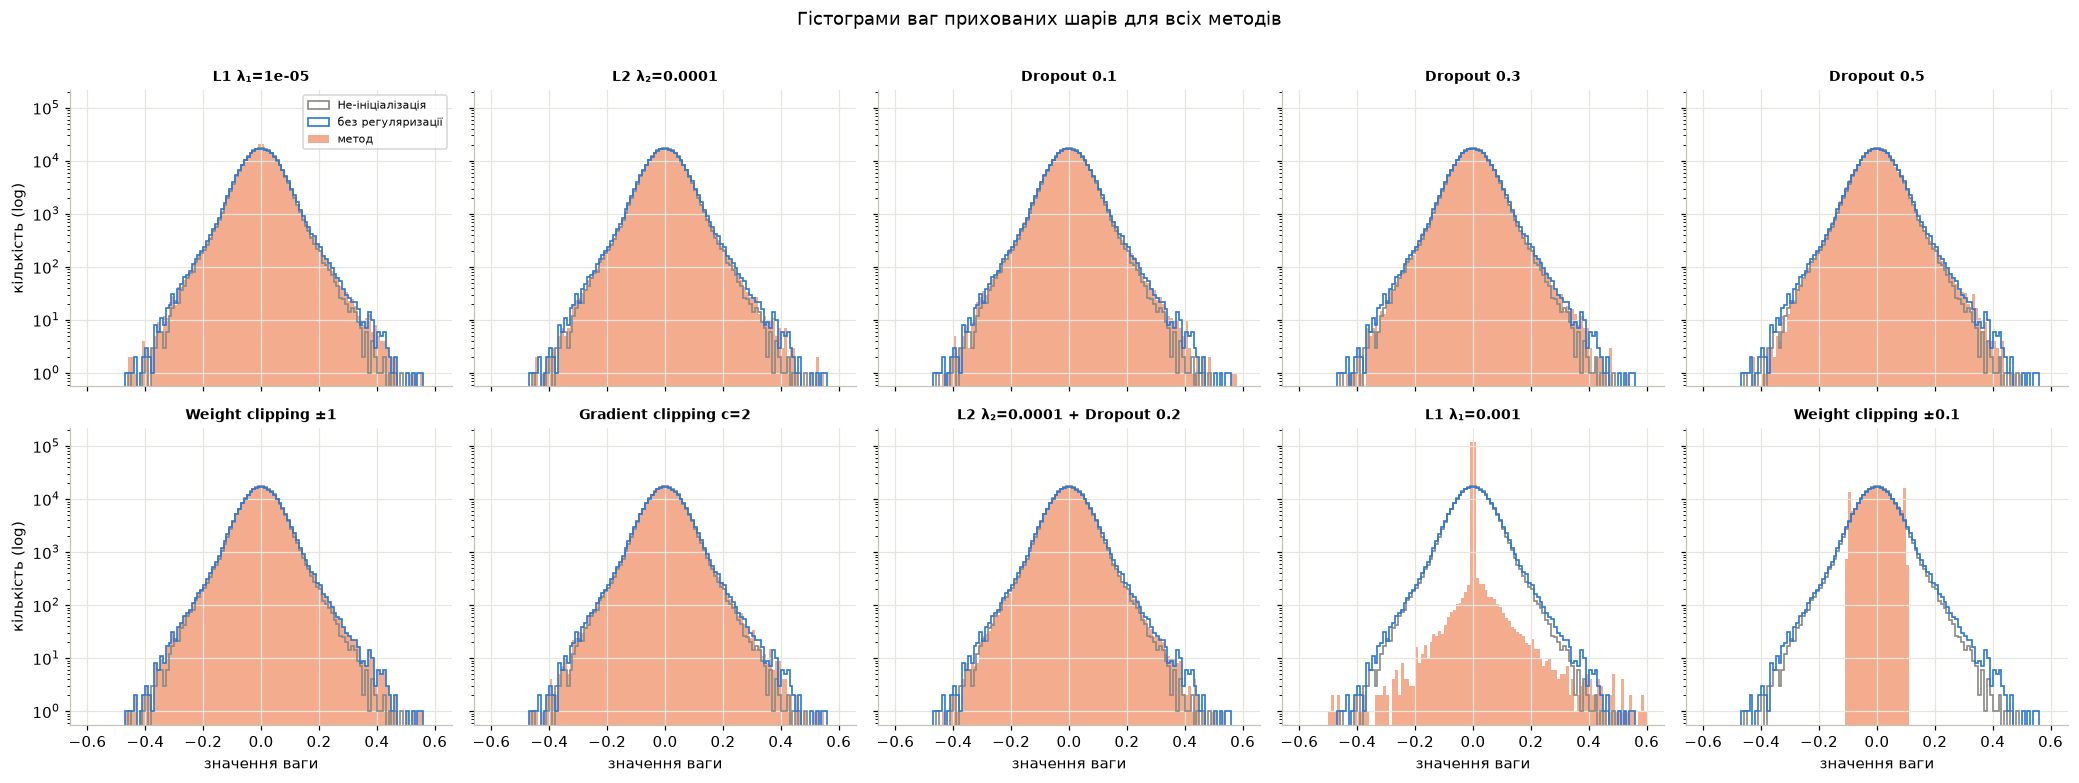

,"|W| < 0.001, %","|W| < 0.01, %","|W| < 0.05, %",std W
метод,,,,
He-ініціалізація,1.481,14.460,63.197,0.061
Без регуляризації,1.410,13.988,61.359,0.064
L2 λ₂=0.0001,1.445,14.295,62.445,0.063
L2 λ₂=0.001,1.789,17.636,72.167,0.051
L2 λ₂=0.01,10.088,71.678,98.766,0.014
L1 λ₁=1e-05,2.938,17.031,63.601,0.062
L1 λ₁=0.0001,30.949,44.867,79.119,0.048
L1 λ₁=0.001,97.393,98.559,99.254,0.014
Dropout 0.1,1.420,14.048,61.577,0.064


In [18]:
grid_names = [name for _, name in summary_order[1:]] + ["L1 λ₁=0.001", "Weight clipping ±0.1"]
fig, axes = plt.subplots(2, 5, figsize=(19, 7), sharex=True, sharey=True)
bins = np.linspace(-0.6, 0.6, 121)
base_weights = hidden_weights(baseline)
for ax, name in zip(axes.ravel(), grid_names):
    ax.hist(np.clip(initial_hidden_weights, -0.6, 0.6), bins=bins, histtype="step", color=COLORS["muted"], lw=1.1, label="He-ініціалізація")
    ax.hist(np.clip(base_weights, -0.6, 0.6), bins=bins, histtype="step", color=COLORS["blue"], lw=1.1, label="без регуляризації")
    ax.hist(np.clip(hidden_weights(experiments[name]["model"]), -0.6, 0.6), bins=bins, color=COLORS["orange"], alpha=0.55, label="метод")
    ax.set_title(name, fontsize=9)
    ax.set_yscale("log")
axes[0, 0].legend(fontsize=7)
for ax in axes[1]:
    ax.set_xlabel("значення ваги")
for ax in axes[:, 0]:
    ax.set_ylabel("кількість (log)")
fig.suptitle("Гістограми ваг прихованих шарів для всіх методів", y=1.01)
plt.tight_layout()
plt.show()

near_zero = pd.DataFrame([{
    "метод": name,
    "|W| < 0.001, %": 100 * np.mean(np.abs(hidden_weights(item["model"])) < 0.001),
    "|W| < 0.01, %": 100 * np.mean(np.abs(hidden_weights(item["model"])) < 0.01),
    "|W| < 0.05, %": 100 * np.mean(np.abs(hidden_weights(item["model"])) < 0.05),
    "std W": item["row"]["std W"],
} for name, item in [("He-ініціалізація", {"model": initial_model, "row": {"std W": initial_hidden_weights.std()}})] + list(experiments.items())])
display(near_zero.set_index("метод").round(3))

**Коментар до розподілу ваг.**

- **Методи, що не змінюють форму розподілу.** Dropout (усі p), gradient clipping, weight clipping ±1 і слабкі L1/L2 дають гістограми, майже ідентичні базовій. Причини різні: Dropout діє на активації, gradient clipping — на розмір кроку, межа ±1 не досягається.
- **Сама базова модель** мало відходить від He-ініціалізації: навчання змінює переважно хвости розподілу.
- **L2 (сильна)** робить розподіл **вужчим**: std 0.064 → 0.014 при $\lambda_2 = 10^{-2}$. Форма лишається дзвоноподібною, без піку в нулі.
- **L1** створює **різкий пік рівно біля нуля** і «важкі» хвости. При $\lambda_1 = 10^{-3}$ 97.4% ваг мають $|W| < 0.001$, а окремі ваги зростають до 0.95.
- **Weight clipping ±0.1** дає обрізаний розподіл із **піками на межах ±0.1**. При ±1 піків немає, бо межа не досягається.
- **Кількість ваг біля нуля.** Фоновий рівень $|W| < 0.01$ після He — 14.5%. Суттєво його підвищують лише L1 (44.9% і 98.6%) і сильна L2 (17.6% і 71.7%). Зміст цього різний: L1 створює **майже точні нулі** (частка $|W| < 0.001$ — 30.9% і 97.4%), а L2 лише **стискає** всі ваги (при $\lambda_2 = 10^{-2}$ $|W| < 0.001$ мають тільки 10.1%).

## 3.3 Мертві нейрони і валідаційна точність

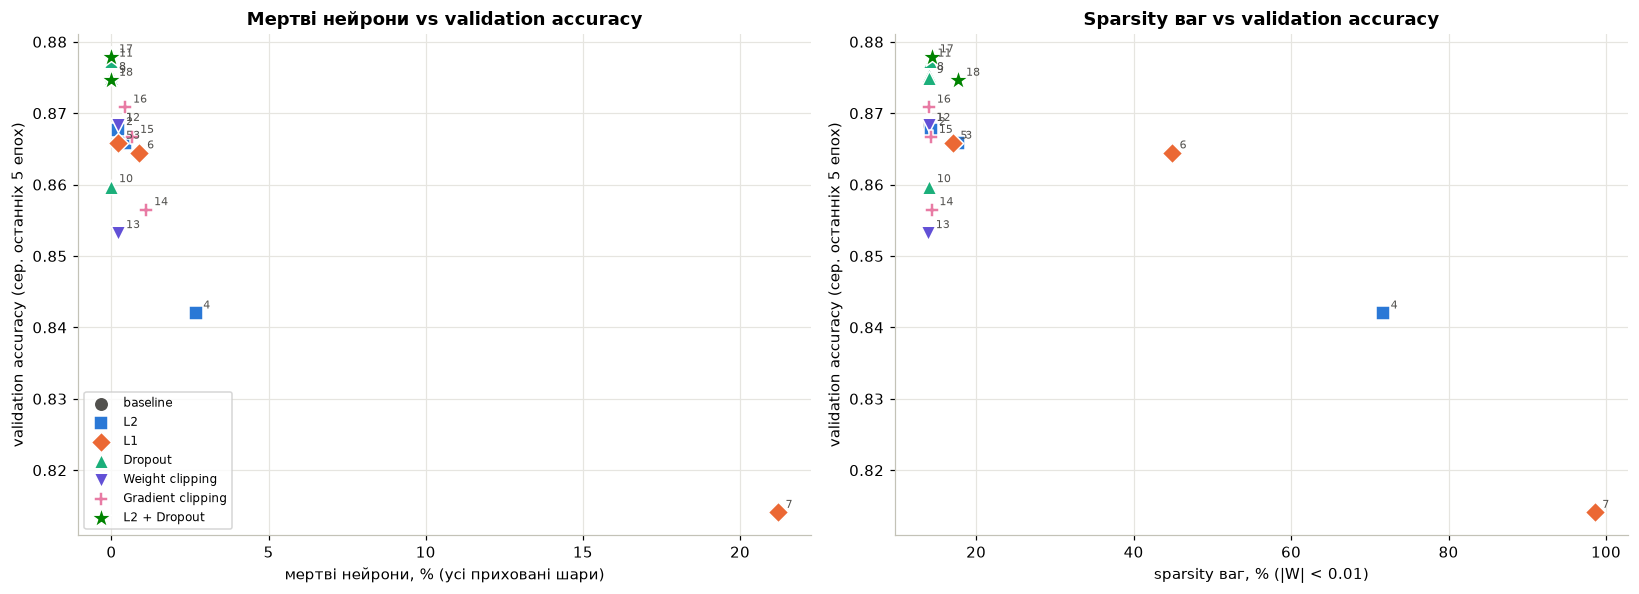

Номери точок на графіках:

,метод,група,"dead, %","sparsity, %",val acc (сер. 5)
№,,,,,
1,Без регуляризації,baseline,0.2,14.0,0.8683
2,L2 λ₂=0.0001,L2,0.2,14.3,0.8677
3,L2 λ₂=0.001,L2,0.4,17.6,0.8658
4,L2 λ₂=0.01,L2,2.7,71.7,0.8420
5,L1 λ₁=1e-05,L1,0.2,17.0,0.8658
6,L1 λ₁=0.0001,L1,0.9,44.9,0.8644
7,L1 λ₁=0.001,L1,21.2,98.6,0.8141
8,Dropout 0.1,Dropout,0.0,14.0,0.8754
9,Dropout 0.3,Dropout,0.0,14.0,0.8750


Кореляція Спірмена з val acc (сер. 5) по 18 експериментах:


  dead, %     : -0.739
  sparsity, % : -0.330


In [19]:
GROUP_STYLE = {
    "baseline": (COLORS["ink"], "o"), "L2": (COLORS["blue"], "s"), "L1": (COLORS["orange"], "D"),
    "Dropout": (COLORS["aqua"], "^"), "Weight clipping": (COLORS["violet"], "v"),
    "Gradient clipping": (COLORS["magenta"], "P"), "L2 + Dropout": (COLORS["green"], "*"),
}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, x_column, x_label in ((axes[0], "dead, %", "мертві нейрони, % (усі приховані шари)"),
                              (axes[1], "sparsity, %", "sparsity ваг, % (|W| < 0.01)")):
    for group, (color, marker) in GROUP_STYLE.items():
        part = all_rows[all_rows["група"] == group]
        ax.scatter(part[x_column], part["val acc (сер. 5)"], color=color, marker=marker, s=90 if marker != "*" else 200,
                   edgecolor="white", linewidth=1, label=group, zorder=3)
    for number, (name, row) in enumerate(all_rows.iterrows(), start=1):
        ax.annotate(str(number), (row[x_column], row["val acc (сер. 5)"]), textcoords="offset points",
                    xytext=(5, 3), fontsize=7, color=COLORS["ink"])
    ax.set(xlabel=x_label, ylabel="validation accuracy (сер. останніх 5 епох)")
axes[0].set_title("Мертві нейрони vs validation accuracy")
axes[1].set_title("Sparsity ваг vs validation accuracy")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

display(Markdown("Номери точок на графіках:"))
display(all_rows[["група", "dead, %", "sparsity, %", "val acc (сер. 5)"]]
        .assign(**{"№": range(1, len(all_rows) + 1)}).reset_index().set_index("№")
        .style.format({"dead, %": "{:.1f}", "sparsity, %": "{:.1f}", "val acc (сер. 5)": "{:.4f}"}))
print(f"Кореляція Спірмена з val acc (сер. 5) по {len(all_rows)} експериментах:")
print(f"  dead, %     : {all_rows['dead, %'].corr(all_rows['val acc (сер. 5)'], method='spearman'):+.3f}")
print(f"  sparsity, % : {all_rows['sparsity, %'].corr(all_rows['val acc (сер. 5)'], method='spearman'):+.3f}")

**Відповіді на питання за діаграмою.**

1. **Чи існує залежність між мертвими нейронами і якістю?** Так. Кореляція Спірмена між часткою мертвих нейронів і val accuracy по 18 експериментах дорівнює −0.74. Але її задають насамперед дві крайні точки: L1 $10^{-3}$ (21.2% мертвих, 0.814) і L2 $10^{-2}$ (2.7%, 0.842). Для решти моделей з 0–1.1% мертвих нейронів точність коливається від 0.853 до 0.878 і залежить від інших чинників.
2. **Чи призводить велика кількість мертвих нейронів до зниження точності?** У наших експериментах обидві моделі з найбільшою часткою мертвих нейронів — найгірші за точністю. Проте мертві нейрони тут **симптом** надмірної регуляризації, а не єдина причина. Навіть у L1 $10^{-3}$ живі 79% нейронів, але майже всі їхні вхідні ваги нульові: модель втрачає точність через загальне обмеження місткості.
3. **Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність?** Так. Базова модель і weight clipping ±0.1 мають по 1 мертвому нейрону (0.2%), але точність 0.8683 і 0.8533. Dropout 0.2 і Dropout 0.5 мають 0 мертвих, але точність 0.8773 і 0.8597. Кількість мертвих нейронів не визначає якість однозначно.
4. **Чи існує оптимальний баланс між sparsity і мертвими нейронами?** Так, його добре видно на L1. При $\lambda_1 = 10^{-4}$ розрідженість 44.9%, мертвих лише 0.9%, а точність 0.8644 — всього −0.4 п.п. від базової. Тобто половину зв'язків можна прибрати майже безкоштовно. Далі ($\lambda_1 = 10^{-3}$) зануляються вже **цілі вектори вхідних ваг нейронів**: нейрони відмирають (21%), і точність падає на 5.4 п.п. Висока sparsity сама по собі не шкодить, поки нейрони лишаються живими. Тому кореляція sparsity з точністю слабша (−0.33), ніж кореляція мертвих нейронів з точністю.

## 3.4 Чи завжди сильніша регуляризація краща?

In [20]:
strength_rows = []
for group, names in (("L2", [f"L2 λ₂={v:g}" for v in L2_VALUES]), ("L1", [f"L1 λ₁={v:g}" for v in L1_VALUES]),
                     ("Dropout", [f"Dropout {v:g}" for v in [0.1, 0.2, 0.3, 0.5]]),
                     ("Gradient clipping", [f"Gradient clipping c={v:g}" for v in sorted(GRAD_CLIP_VALUES, reverse=True)]),
                     ("Weight clipping", ["Weight clipping ±1", "Weight clipping ±0.1"])):
    for strength, name in enumerate(names, start=1):
        row = experiments[name]["row"]
        strength_rows.append({"метод": group, "сила (1 — найслабша)": strength, "налаштування": row["параметр"],
                              "train acc (сер. 5)": row["train acc (сер. 5)"], "val acc (сер. 5)": row["val acc (сер. 5)"],
                              "розрив train − val": row["train acc (сер. 5)"] - row["val acc (сер. 5)"],
                              "dead, %": row["dead, %"]})
base_row = experiments["Без регуляризації"]["row"]
display(Markdown(f"Базова модель: train acc {base_row['train acc (сер. 5)']:.4f}, val acc {base_row['val acc (сер. 5)']:.4f}, "
                 f"розрив {base_row['train acc (сер. 5)'] - base_row['val acc (сер. 5)']:.4f}"))
display(pd.DataFrame(strength_rows).set_index(["метод", "сила (1 — найслабша)"]).round(4))

final_names = ["Без регуляризації", all_rows["val acc (сер. 5)"].idxmax()]
test_rows = []
for name in final_names:
    test_loss, test_accuracy = experiments[name]["model"].evaluate(X_test, y_test)
    test_rows.append({"модель": name, "test accuracy": test_accuracy, "test loss": test_loss})
display(Markdown("**Фінальна перевірка на офіційному тесті** (використовується один раз — для базової моделі та найкращої за Validation):"))
display(pd.DataFrame(test_rows).set_index("модель").round(4))

Базова модель: train acc 0.9226, val acc 0.8683, розрив 0.0544

налаштування  train acc (сер. 5)  \
метод             сила (1 — найслабша)                                    
L2                1                     λ₂ = 0.0001              0.9201   
                  2                      λ₂ = 0.001              0.9089   
                  3                       λ₂ = 0.01              0.8500   
L1                1                      λ₁ = 1e-05              0.9173   
                  2                     λ₁ = 0.0001              0.9039   
                  3                      λ₁ = 0.001              0.8190   
Dropout           1                         p = 0.1              0.9158   
                  2                         p = 0.2              0.9128   
                  3                         p = 0.3              0.9041   
                  4                         p = 0.5              0.8790   
Gradient clipping 1                           c = 2              0.9192   
                  2                           c = 1              0.8948   
                  3                         c = 0.5              0.8756   
Weight clipping   1                         c_w = 1              0.9226   
                  2                       c_w = 0.1              0.8674   

                                        val acc (сер. 5)  розрив train − val  \
метод             сила (1 — найслабша)                                         
L2                1                               0.8677              0.0524   
                  2                               0.8658              0.0432   
                  3                               0.8420              0.0080   
L1                1                               0.8658              0.0515   
                  2                               0.8644              0.0395   
                  3                               0.8141              0.0049   
Dropout           1                               0.8754              0.0404   
                  2                               0.8773              0.0355   
                  3                               0.8750              0.0291   
                  4                               0.8597              0.0193   
Gradient clipping 1                               0.8708              0.0484   
                  2                               0.8666              0.0282   
                  3                               0.8565              0.0192   
Weight clipping   1                               0.8683              0.0544   
                  2                               0.8533              0.0142   

                                        dead, %  
метод             сила (1 — найслабша)           
L2                1                      0.2232  
                  2                      0.4464  
                  3                      2.6786  
L1                1                      0.2232  
                  2                      0.8929  
                  3                     21.2054  
Dropout           1                      0.0000  
                  2                      0.0000  
                  3                      0.0000  
                  4                      0.0000  
Gradient clipping 1                      0.4464  
                  2                      0.6696  
                  3                      1.1161  
Weight clipping   1                      0.2232  
                  2                      0.2232

**Фінальна перевірка на офіційному тесті** (використовується один раз — для базової моделі та найкращої за Validation):

,test accuracy,test loss
модель,,
Без регуляризації,0.8619,0.3952
L2 λ₂=0.0001 + Dropout 0.2,0.8681,0.3730


**Чи завжди збільшення сили регуляризації покращує узагальнення? Ні.**

Таблиця показує спільну закономірність для всіх методів:

- **розрив train − val монотонно зменшується** зі зростанням сили, тобто перенавчання слабшає;
- **val accuracy при цьому не зростає монотонно.** Для Dropout вона має форму перевернутої «U»: 0.8754 → **0.8773** → 0.8750 → 0.8597. Для L2, L1, weight clipping і gradient clipping вона з посиленням лише спадає.

**Коли регуляризація допомагає.** Слабка або помірна регуляризація (Dropout 0.1–0.3, L2 $10^{-4}$–$10^{-3}$, L1 до $10^{-4}$, gradient clipping $c = 2$) зменшує перенавчання, майже не обмежуючи здатність моделі вивчити Train. Перенавчання базової моделі помірне (розрив 5.4 п.п., мінімум val loss на 26-й епосі), тому користь невелика: найкращий Dropout 0.2 дає +0.9 п.п. середньої val accuracy. Фінальна перевірка на тесті це підтверджує: 0.8619 у базової моделі проти 0.8681 у найкращої за Validation (L2 + Dropout 0.2).

**Коли регуляризація шкодить.** Сильна регуляризація (L2 $10^{-2}$, L1 $10^{-3}$, Dropout 0.5, weight clipping ±0.1, gradient clipping $c = 0.5$) зменшує розрив до 0.5–2 п.п. ціною падіння **train** accuracy до 0.82–0.88. Модель уже не може добре вивчити навіть навчальні дані — це **недонавчання**.

**Різниця між поняттями:**

- **Мала величина ваг** — ваги стиснуті, але не нульові (типово для L2). Нейрон працює, лише з меншим «підсиленням» сигналу.
- **Нульова або майже нульова вага** ($|W| < 0.01$) — окремий **зв'язок** фактично відсутній (типово для L1). Сам нейрон може лишатися активним завдяки іншим входам.
- **Неактивний нейрон** — нейрон, що видає 0 для **конкретного** об'єкта ($Z \le 0$). Це нормальна властивість ReLU: кожен нейрон неактивний на частині даних, і це дає розріджене кодування.
- **Мертвий нейрон** — неактивний на **всіх** об'єктах Train. Він не передає сигнал і не отримує градієнта, тому сам «ожити» не може. Від нейронів, тимчасово вимкнених Dropout, його відрізняє те, що ті вимикаються випадково й лише на один крок.
- **Надмірно регуляризована модель** — місткість обмежено настільки, що train accuracy падає майже до val accuracy (L1 $10^{-3}$: 0.819 / 0.814; L2 $10^{-2}$: 0.850 / 0.842). Розрив малий, але через недонавчання, а не завдяки кращому узагальненню.

## Висновки

1. **Реалізація.** Повнозв'язну мережу 784 → 256 → 128 → 64 → 10 (ReLU, Softmax, cross-entropy, He-ініціалізація, mini-batch SGD) реалізовано з нуля на NumPy. Backpropagation перевірено чисельним диференціюванням: відносна похибка ≤ $1.1 \cdot 10^{-8}$, у тому числі з L1, L2 і Dropout. Збереження у `.npz` і відновлення працюють точно: $\max|\Delta P| = 0$, класи збігаються на всіх 10 000 об'єктах.
2. **Базова модель.** Val accuracy ≈ 0.868 (тест 0.862). Після ~26-ї епохи модель перенавчається (розрив train − val 5.4 п.п.), має лише 1 мертвий нейрон, а 14% «майже нульових» ваг — успадкований від He-ініціалізації фон.
3. **Найкращі методи** — Dropout 0.2 (0.877) і L2 + Dropout 0.2 (0.878, тест 0.868). Комбінація з $\lambda_2 = 10^{-3}$ дає найнижчий val loss (0.341), але точність не вища за чистий Dropout: ефекти складаються, синергії за точністю немає.
4. **L1 створює справжню розрідженість.** При $\lambda_1 = 10^{-4}$ 45% ваг майже нульові без втрати точності, а сильна L1 вбиває 21% нейронів і знижує точність до 0.814. **L2 стискає ваги без нулів**; сильна L2 веде до недонавчання.
5. **Clipping.** Weight clipping ±1 у цій мережі неактивний, ±0.1 створює піки на межах і недонавчання. Gradient clipping з $c \le 1$ обрізає кожен крок, тобто зменшує ефективний learning rate: втрати стабільніші, але точність нижча.
6. **Мертві нейрони і sparsity.** Мертві нейрони пов'язані з низькою точністю (ρ = −0.74), але як симптом надмірної регуляризації. Моделі з однаковою кількістю мертвих нейронів мають різну точність, а висока sparsity сама по собі не шкодить, поки нейрони живі.
7. **Головний висновок.** Сильніша регуляризація завжди зменшує розрив train − val, але покращує узагальнення лише до певної межі. Далі вона обмежує місткість моделі й веде до недонавчання.